# CAT vs DOG vs NOT 01/04: 프로토콜, 데이터, 진단
진단 기반 처방(T)과 일괄 확대 처방(U)의 차이와 원인을 사전등록 방식으로 검증하는 실험의 첫 단계입니다. test는 사용하지 않습니다.

## 실행
`MyDrive/DiagnoseOrScaleUp/dataset.zip`을 준비한 뒤 Colab GPU에서 01→04 순서로 실행합니다. 중단되면 같은 노트북을 다시 실행하면 이어서 진행됩니다.

In [2]:
# 실행 설정 (결과에 영향 없음)
PROJECT_DIR = '/content/drive/MyDrive/DiagnoseOrScaleUp'   # 데이터·결과 폴더
SMOKE = False               # True: 소규모 점검 실행
FORCE_RESTART = set()       # 처음부터 다시 학습할 run (예: {'conf_hard_s43'})
NUM_WORKERS = None          # None: 자동
SHOW_FIGURES = True
DRIVE_CKPT_EVERY = 5        # Drive 체크포인트 저장 간격(epoch)
PURGE_TRASHED_CKPT = True   # 휴지통의 이전 체크포인트 삭제
SPLIT_SOURCE = 'auto'       # 'auto': 기존 분할 재검증 후 재사용, 'new': 새로 생성

import os, sys, subprocess
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    subprocess.run('apt-get -qq install -y fonts-nanum > /dev/null 2>&1', shell=True)    # 한글 폰트
PROJECT_DIR = os.environ.get('CDN_PROJECT_DIR', PROJECT_DIR)
SMOKE = os.environ.get('CDN_SMOKE', '1' if SMOKE else '0') == '1'
if not os.path.exists(os.path.join(PROJECT_DIR, 'dataset.zip')) and not os.path.exists(
        os.path.join(PROJECT_DIR, 'experiments_full' + ('_smoke' if SMOKE else ''), '_shared')):
    raise FileNotFoundError(f'{PROJECT_DIR}/dataset.zip 이 없습니다')
print('설정 완료 →', PROJECT_DIR, '| SMOKE', SMOKE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
설정 완료 → /content/drive/MyDrive/DiagnoseOrScaleUp | SMOKE False


## 엔진 셀 E1~E7
네 노트북에 동일하게 들어 있는 공통 코드입니다. 원문 해시가 잠금 파일에 기록되므로 수정하지 않습니다.

In [3]:
# ══ 엔진 셀 E1/7 · 설정 · 규칙 · 가설 (실험 전에 잠기는 모든 값) — 수정 금지 (네 노트북에 똑같이 들어 있음) ══
# -*- coding: utf-8 -*-
"""
CAT vs DOG vs NOT 전체 실험 엔진 (원래 연구 질문 + 가설 H1~H10 + 목적 ①②③) — 셀 E1~E7

연구 질문: 같은 데이터 · 학습 레시피 · 학습 예산에서, 오류 방향을 진단하고 그 지점만 겨냥한 개선(T)과
          전체 정확도만 보고 모델·증강을 일괄로 키운 개선(U)은 정말 다른 결과를 내는가? 다르다면, 그 차이는 무엇 때문인가?

이 엔진 셀 E1~E7 은 네 노트북에 글자 하나까지 똑같이 들어 있습니다(별도 .py 파일 없음). 셀 원문의 SHA-256 이 모든 잠금
파일에 기록되며, 한 글자라도 바뀌면 이후 단계가 실행을 거부합니다.
  01_protocol_data_diagnosis      : 프로토콜 잠금 · 데이터 누수 감사/분할 · 진단용 baseline · 진단(target·실패 유형) 잠금
  02_prescriptions_preregistration: T 처방(진단 규칙) · U 처방(집계 지표만) · arm 등록 · epoch 보정 · 학습률 선택(H10) · 사전 등록
  03_confirmatory_training        : 난이도 × seed 마다 모든 arm 을 같은 루프에서 나란히(lockstep) 학습 · 학습 감사
  04_test_and_hypotheses          : test 1회 개방 · H1~H10 · 목적 ①②③ 판정 · 최종 보고서
"""
import os, sys, io, re, json, math, time, random, hashlib, shutil, zipfile, datetime, dataclasses, itertools, copy
import multiprocessing as mp
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Sampler
import torchvision
import torchvision.transforms as T
import torchvision.models as tvm

try:
    from tqdm.auto import tqdm
except Exception:  # pragma: no cover
    def tqdm(x, **k):
        return x
from scipy import stats as sps

ENGINE_VERSION = 'cdn-full-2.1'
ENGINE_PART_ORDER = ['E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7']
_ENGINE_PARTS = globals().get('_ENGINE_PARTS', {})


def _register_engine_part(name):
    """엔진 셀 마지막 줄에서 호출: 방금 실행된 셀의 원문(IPython _ih[-1])을 해시해 등록합니다.
    네 노트북의 엔진 셀은 글자 하나까지 같아야 하며, 다르면 잠금 대조에서 거부됩니다."""
    try:
        src = get_ipython().user_ns['_ih'][-1]          # noqa: F821  (IPython 커널 전역)
    except Exception as e:
        raise PipelineError(f'엔진 셀 원문을 읽을 수 없습니다 (Jupyter/Colab 에서 셀로 실행하세요): {e}')
    if f"_register_engine_part('{name}')" not in src:
        raise PipelineError(f'엔진 셀 {name} 을 셀 단위로 순서대로 실행하세요')
    _ENGINE_PARTS[name] = hashlib.sha256(src.encode('utf-8')).hexdigest()

class PipelineError(RuntimeError):
    pass

class IntegrityError(RuntimeError):
    pass

class ControlFailure(RuntimeError):
    pass

class TestLockError(RuntimeError):
    pass

# ════════════════════════════════════════════════════════════════════════════════════════════════
# 1. 고정 상수와 실험 설계 (01 에서 프로토콜로 잠김 — 결과를 보기 전에 정해진 값)
# ════════════════════════════════════════════════════════════════════════════════════════════════
NOT_TYPES = ['easy', 'mid', 'hard']
SHORT_CLASS = ['cat', 'dog', 'not']                     # ImageFolder 알파벳 순: cat=0, dog=1, not-*=2
ANIMALS = ['cat', 'dog']
K = 3
DIRECTIONS = [f'{a}->{b}' for a in SHORT_CLASS for b in SHORT_CLASS if a != b]
CANDIDATES = ['cat->not', 'dog->not', 'not->cat', 'not->dog']
CONTROL_DIRS = ['cat->dog', 'dog->cat']

# 기존 프로젝트와 같은 공통 학습 레시피 (보고서 §5.3). 모든 arm 이 이 dict 하나를 공유합니다.
RECIPE = dict(
    img_size=224, norm_mean=(0.485, 0.456, 0.406), norm_std=(0.229, 0.224, 0.225),
    base_aug=dict(crop_scale=(0.7, 1.0), hflip=0.5, jitter=(0.3, 0.3, 0.3, 0.08)),
    head=dict(hidden=256, batchnorm=True, act='relu', dropout=0.5),
    optimizer='AdamW', lr=2e-4, weight_decay=0.01, betas=(0.9, 0.999),
    batch=64, warmup_epochs=3, min_lr_ratio=0.01, scheduler='epoch-wise linear warmup + cosine to min_lr_ratio at E',
    loss='class-weighted soft-target cross-entropy + label smoothing (보고서 §5.3)', label_smoothing=0.10,
    class_weighting='balanced: w_c = N / (K · N_c), train split, 난이도별',
    grad_clip=1.0, amp=True, channels_last=True,
    ema_decay=0.999, ema_warmup='min(decay, (1+t)/(10+t))',
    early_stopping=None, model_selection='final epoch (EMA 가 있는 arm 은 EMA, 없으면 원 가중치) — validation 으로 고르지 않음',
    val_ratio=0.20, split_seed=42, cache_short_side=256,
    near_dup_hamming=dict(h64=4, h256=32), drop_train_test_overlap=True, exclude_label_conflicts=True,
    eval='Resize(img,img) 단일 뷰',
)

# 후보 백본 (torchvision 공식 가중치 · 공식 문서의 ImageNet top-1 · GFLOPs). 진단 규칙 D 가 이 표로 고릅니다.
BACKBONES = {
    'resnet18': dict(weights='IMAGENET1K_V1', imagenet_top1=69.758, gflops=1.81),
    'resnet50': dict(weights='IMAGENET1K_V1', imagenet_top1=76.130, gflops=4.09),
    'efficientnet_b0': dict(weights='IMAGENET1K_V1', imagenet_top1=77.692, gflops=0.39),
}
BASELINE_BACKBONE = 'resnet18'

AUG_PARAMS = dict(
    random_erasing=dict(scale=(0.02, 0.4), ratio=(0.3, 3.3), fill='N(0,1) noise in normalized space'),
    mix=dict(batch_prob=0.5, cutmix_alpha=1.0, mixup_alpha=0.4, cutmix_share_when_both=0.5, mixed_fraction=1.0,
             pairing='배치를 겹치지 않는 B/2 쌍으로 완전 매칭 → 쌍 맞교환 혼합 (클래스별 label mass 정확 보존)'),
    randaugment=dict(num_ops=2, magnitude=9),
    coupling='모든 arm 이 같은 배치·같은 기본 증강·같은 난수 사건을 받습니다. RE 는 표본별 공유 균등난수 u_i < p 로 결정 → '
             'p 가 다른 arm 끼리도 최대한 같은 이미지가 지워지고, 같은 정책의 arm 끼리는 완전히 같습니다.',
)

# 진단 규칙 (01 학습 전에 잠김). 보고서 §6.2·§7.1 의 실패 유형 A~E 를 수치 조건으로 코드화.
DIAGNOSIS_RULES = dict(
    target_min_rate=0.02,          # 후보 방향 중 validation 오류율 ≥ 2% → target (보고서 §7.1: not→동물 ≤ 2%p 는 보류)
    A_random_erasing=dict(if_='동물→not target 존재 AND 그 오류 중 확신도 ≥ 0.9 비율 ≤ 0.10 (애매하게 틀림 = 가림·부분 장면)',
                          conf=0.9, max_high_conf_share=0.10, p=0.5),
    B_cutmix=dict(if_='target 존재 AND 과적합(train-clean acc − val acc) ≥ 0.03', min_overfit_gap=0.03),
    C_mixup=dict(if_='not→동물 target 존재 (경계 양방향 붕괴)'),
    D_backbone=dict(if_='후보 4방향 모두 target AND 판정 기준 이동 최대 macro-F1 이득 ≤ 0.002 (비율 아닌 표현 한계)',
                    max_logit_shift_gain=0.002, choose='ImageNet top-1 최고 백본 (동률이면 GFLOPs 작은 것) — Kornblith 2019'),
    E_ema=dict(if_='baseline val 정확도 epoch 간 변화량 중앙값(warm-up 이후) ≥ 0.0025', min_fluct=0.0025),
    pairing='T 의 혼합 짝 = target 방향이 잇는 클래스 쌍 (예: cat↔not, dog↔not)',
)
# U 설계 규칙: 방향 정보 없이 집계 지표만 입력 (보고서 §7.2). 세 난이도에 같은 처방을 일괄 적용.
U_RULES = dict(
    capacity=dict(if_='정확도가 EASY→HARD 로 ≥ 0.03 하락 OR 어느 난이도든 macro-F1 < 0.90', then='resnet50'),
    regularize=dict(if_='어느 난이도든 과적합 ≥ 0.03', then='RandAugment(2,9) + CutMix·MixUp 무작위 짝 + RE p=0.25'),
    stabilize=dict(if_='어느 난이도든 val 흔들림 ≥ 0.0025', then='EMA'),
    re_p=0.25, inputs_allowed=['accuracy', 'macro_f1', 'precision', 'recall', 'overfit_gap', 'val_fluctuation'],
)

SEEDS = (42, 43, 44, 45, 46)       # 확증 seed (모든 arm 공통, 짝지은 비교). 5개 → seed 성분 자유도 4 (3개면 2). 01 실행 전에만 변경.
DIAGNOSIS_SEEDS = (42, 43, 44)     # 진단용 baseline: 3개 seed 의 validation 혼동을 합산 → 2% 경계 근처 target 판정의 잡음 감소
EPOCHS = dict(
    diagnosis=40,
    grid=(40, 60, 80), extension_factor=1.5, max_extensions=1,
    calibration_seeds=(40, 41), calibration_arms=('T', 'U'),   # 보정 전용 seed 2개의 validation 평균 (확증 seed 와 분리)
    calibration_nt_rule='적격 난이도 중 epoch 당 optimizer step 이 가장 적은 난이도',
    tol_factor=0.5, tol_macro_f1=0.005,
    rule=("E* = 격자에서 가장 작은 E 중: 두 arm 각각 val target/1k 가 더 긴 E 들의 최솟값 + tol 이내, macro-F1 이 더 긴 E 들의 "
          "최댓값 − 0.005 이내, T−U val 차이가 E_max 와 tol 이내. E_max 가 직전보다 tol 넘게 좋아졌으면 ×1.5 를 한 번 추가."),
)
LR_FAIRNESS = dict(grid=(1e-4, 2e-4, 4e-4), seeds=(40, 41), criterion='final-epoch val macro-F1, 선택 seed 평균 (보고서 §9.6)',
                   arms=('T', 'U'), nt='hard')
FOCUS_NT = 'hard'                  # H4~H10 을 검정하는 난이도 (보고서의 가설 정의)
FACTORIAL_BACKBONES = ('resnet18', 'resnet50', 'efficientnet_b0')

STAT_PLAN = dict(
    alpha=0.05, bootstrap_B=10000, bootstrap_seed=20261002, ece_bins=15,
    inference='hybrid: SE² = s²(seed별 대비)/S + Var(test 이미지 재표본 bootstrap, seed 평균); df = Welch–Satterthwaite; t 구간·t 검정',
    margin_per1000=dict(relative=0.10, floor=1.0, reference='진단 baseline 의 validation 같은 방향군 오류 /1,000장'),
    margin_rate_pp=dict(relative=0.10, floor=0.5, reference='진단 baseline 의 validation 같은 방향 오류율 (%p)'),
    non_inferiority=dict(macro_f1=0.01, recall_pp=1.0),
    holm=dict(H1_family='난이도별 target family (적격 난이도 전체)', H1_direction='모든 (난이도, target 방향)',
              H2='난이도별 DiD', confirmatory_focus='H4·H5·H7·H8·H9·H10', mcnemar='난이도×seed'),
    never=['p > .05 를 "효과 없음/동등" 으로 해석 (동등은 TOST 로만)',
           'target 유의 + control 비유의 를 특이성 근거로 사용 (특이성은 DiD 로만)'],
)

HYPOTHESES = {
    'H1': 'T 는 자신이 겨냥한 오류 방향(군)에서 U 보다 덜 틀린다 (난이도별)',
    'H2': '그 차이는 겨냥 방향에서만 나타나고 대조 방향(cat↔dog)에서는 나타나지 않는다 (DiD)',
    'H3': 'T 의 개선은 다른 곳을 망쳐서 얻은 것이 아니다 (원래 클래스 재현율 · 역방향 오류 · macro-F1 비열등)',
    'H4': '처방을 고정하고 백본만 EfficientNet-B0 로 바꿔도 겨냥 방향 오류가 준다 (EffB0 − R50 주효과, HARD)',
    'H5': '백본을 고정해도 진단 기반 처방이 일괄 처방보다 낫다 (T 처방 − U 처방 주효과, HARD)',
    'H6': '처방 효과가 백본에 따라 달라진다 (상호작용, 탐색)',
    'H7': '혼합 짝을 진단된 쌍으로 제한하면 무작위 짝보다 낫다 (T − T_randpair, HARD)',
    'H8': 'HARD 의 T < U 가 seed 를 바꿔도 유지된다',
    'H9': '혼합 배치에서 클래스 가중치를 끄면 not→cat 오류가 준다 (부작용: cat→not 가드)',
    'H10': '두 방법의 학습률을 각각 validation 으로 최적화한 뒤에도 T* < U* 가 유지된다 (HARD)',
}
PURPOSES = {
    'P1': '① 진단의 유용성 — 진단이 지목한 경계는 개선 가능하고(D1), 대조 경계는 두 처방이 같으며(D2), '
          '판정 기준 이동으로는 풀리지 않는다(D3)',
    'P2': '② 공정한 비교 — 같은 조건에서 T 와 U 가 겨냥 방향에서만 다른가 (H1·H2·H3·H8)',
    'P3': '③ 원인 분리 — 차이가 처방·백본·쌍 한정·클래스 가중치·학습률 중 무엇 때문인가 (H4~H7·H9·H10)',
}

# 기존 보고서 수치 (규칙 자체시험과 최종 보고서의 맥락 비교에만 사용 — 판정에 쓰지 않음)
LEGACY = dict(
    val_rates={'easy': {'cat->not': .088, 'dog->not': .032, 'not->cat': .012, 'not->dog': .006, 'cat->dog': .068, 'dog->cat': .071},
               'mid': {'cat->not': .121, 'dog->not': .080, 'not->cat': .042, 'not->dog': .017, 'cat->dog': .062, 'dog->cat': .093},
               'hard': {'cat->not': .204, 'dog->not': .134, 'not->cat': .055, 'not->dog': .054, 'cat->dog': .066, 'dog->cat': .049}},
    acc={'easy': .950, 'mid': .890, 'hard': .835}, macro_f1={'easy': .911, 'mid': .865, 'hard': .819},
    high_conf_a2n={'easy': 0.0, 'mid': 0.0, 'hard': 0.015}, logit_gain={'easy': .0007, 'mid': .0012, 'hard': .0006},
    overfit={'easy': .050, 'mid': .095, 'hard': .148}, fluct={'easy': .0037, 'mid': .0062, 'hard': .0107},
    results={'T_minus_U_hard': (-25.0, -34.8, -15.0), 'T_minus_U_easy': (-0.9, -3.0, 1.3), 'T_minus_U_mid': (-0.9, -7.0, 5.3),
             'H4': (-23.8, -31.3, -15.8), 'H5': (-1.2, -7.6, 4.8), 'H6': (-3.3, -16.2, 9.0), 'H7': (-0.5, -8.3, 7.4),
             'H8': (-18.3, -28.4, -8.1), 'H9_pp': (-2.18, -3.01, -1.37), 'H10': (-16.4, -26.0, -7.1)},
)

# ════════════════════════════════════════════════════════════════════════════════════════════════
# 2. 실행 문맥 (노트북이 init() 으로 설정)
# ════════════════════════════════════════════════════════════════════════════════════════════════
class _Ctx:
    project_dir = None; local_root = None; exp_root = None; role = None
    smoke = False; show_figures = True; num_workers = None; strict_det = False
    keep_ckpt = False; force_restart = set(); split_source = 'auto'
    device = torch.device('cpu'); amp = False; channels_last = False

CTX = _Ctx()
SMOKE_OVERRIDES = dict(img_size=32, batch=16, warmup_epochs=1, pretrained=False, seeds=(42, 43), diagnosis_seeds=(42,),
                       subsample=dict(train=48, val=24, test=24), diag_epochs=2, grid=(2, 3), lr_grid_extra=True,
                       bootstrap_B=300, train_clean_n=60)

_register_engine_part('E1')


In [4]:
# ══ 엔진 셀 E2/7 · 유틸리티 · 잠금 · 경로 · 체크포인트 휴지통 정리 — 수정 금지 (네 노트북에 똑같이 들어 있음) ══
# ════════════════════════════════════════════════════════════════════════════════════════════════
# 3. 유틸리티 · 잠금 파일 · 난수 스트림
# ════════════════════════════════════════════════════════════════════════════════════════════════
def now_iso():
    return datetime.datetime.now().isoformat(timespec='seconds')


def _jsonable(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (set, frozenset)):
        return sorted(o, key=str)
    if isinstance(o, tuple):
        return list(o)
    if isinstance(o, torch.Tensor):
        return o.tolist()
    return str(o)


def canonical(obj):
    return json.dumps(obj, sort_keys=True, default=_jsonable, ensure_ascii=False)


def normalize_json(obj):
    return json.loads(canonical(obj))


def full_hash(obj):
    return hashlib.sha256(canonical(normalize_json(obj)).encode()).hexdigest()


def fingerprint(obj, n=16):
    return full_hash(obj)[:n]


def sha256_file(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()


def engine_hash():
    """엔진 셀 E1~E7 원문의 SHA-256 — 모든 잠금 파일에 기록되어 01~04 가 같은 코드를 쓰는지 대조합니다."""
    missing = [p for p in ENGINE_PART_ORDER if p not in _ENGINE_PARTS]
    if missing:
        raise PipelineError(f'엔진 셀 {missing} 이 실행되지 않았습니다 — 노트북을 위에서부터 순서대로 실행하세요')
    return hashlib.sha256('|'.join(_ENGINE_PARTS[p] for p in ENGINE_PART_ORDER).encode()).hexdigest()


def atomic_write_bytes(path, data):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tmp = f"{path}.tmp-{os.getpid()}"
    with open(tmp, 'wb') as f:
        f.write(data)
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp, path)


def write_json(path, obj):
    atomic_write_bytes(path, json.dumps(obj, indent=2, ensure_ascii=False, default=_jsonable).encode())


def read_json(path, default=None):
    if not os.path.exists(path):
        return default
    with open(path, encoding='utf-8') as f:
        return json.load(f)


def write_csv(path, df):
    atomic_write_bytes(path, df.to_csv(index=False).encode('utf-8-sig'))


def append_jsonl(path, obj):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, 'a', encoding='utf-8') as f:
        f.write(json.dumps(obj, ensure_ascii=False, default=_jsonable) + '\n')
        f.flush()
        os.fsync(f.fileno())


def write_locked(path, body, kind):
    body = normalize_json(body)
    h = full_hash(body)
    write_json(path, dict(kind=kind, sha256=h, written_at=now_iso(), engine_version=ENGINE_VERSION,
                          engine_sha256=engine_hash(), body=body))
    atomic_write_bytes(path + '.sha256', (h + '\n').encode())
    return h


def read_locked(path, kind):
    doc = read_json(path)
    if doc is None:
        raise PipelineError(f"잠금 문서가 없습니다: {path} — 앞 단계 노트북을 먼저 실행하세요")
    if doc.get('kind') != kind:
        raise IntegrityError(f"{path}: 문서 종류 {doc.get('kind')} ≠ {kind}")
    h = full_hash(doc['body'])
    if h != doc.get('sha256'):
        raise IntegrityError(f"{path}: 본문 해시가 기록과 다릅니다 (사후 수정 또는 손상)")
    side = path + '.sha256'
    if not os.path.exists(side) or open(side).read().strip() != h:
        raise IntegrityError(f"{path}: .sha256 옆 파일과 해시가 다릅니다")
    if doc.get('engine_sha256') != engine_hash():
        raise IntegrityError(f"{path}: 이 잠금은 다른 엔진 파일로 만들어졌습니다 (cdn_full.py 가 바뀜). "
                             f"엔진을 고쳤다면 실험을 처음부터 다시 시작해야 합니다.")
    return doc['body'], h


def diff_dicts(a, b, prefix=''):
    out = []
    a, b = normalize_json(a or {}), normalize_json(b or {})
    for k in sorted(set(a) | set(b)):
        va, vb = a.get(k, '<없음>'), b.get(k, '<없음>')
        if isinstance(va, dict) and isinstance(vb, dict):
            out += diff_dicts(va, vb, f"{prefix}{k}.")
        elif canonical(va) != canonical(vb):
            out.append(f"{prefix}{k}: {str(va)[:80]} → {str(vb)[:80]}")
    return out


def lock_or_verify(path, body, kind):
    """처음이면 잠그고, 이미 있으면 같은 내용인지 확인 (재실행 안전). 다르면 거부."""
    if os.path.exists(path):
        old, h = read_locked(path, kind)
        d = diff_dicts(old, body)
        if d:
            raise IntegrityError(f"{os.path.basename(path)} 가 이미 다른 내용으로 잠겨 있습니다 (결과를 본 뒤 변경 금지):\n  "
                                 + '\n  '.join(d[:12]))
        print(f"  ✔ {os.path.basename(path)} 재검증 일치 ({h[:16]})")
        return h
    h = write_locked(path, body, kind)
    print(f"  🔒 {os.path.basename(path)} 잠금 ({h[:16]})")
    return h


def stream_seed(*parts):
    h = hashlib.sha256('|'.join(map(str, parts)).encode()).digest()
    return int.from_bytes(h[:4], 'little') & 0x7FFFFFFF


def seed_all(seed):
    seed = int(seed) % (2 ** 31)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def torch_rng_get():
    s = dict(cpu=torch.get_rng_state())
    if torch.cuda.is_available():
        s['cuda'] = torch.cuda.get_rng_state()
    return s


def torch_rng_set(s):
    torch.set_rng_state(s['cpu'].cpu())
    if torch.cuda.is_available() and 'cuda' in s:
        torch.cuda.set_rng_state(s['cuda'].cpu())


def torch_save_atomic(obj, path):
    """같은 폴더의 임시 파일에 저장 → fsync → rename. 저장 도중 끊겨도 기존 체크포인트는 그대로입니다
    (최대 공간: 기존 + 새 파일 1벌)."""
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tmp = f"{path}.tmp-{os.getpid()}"
    try:
        with open(tmp, 'wb') as f:
            torch.save(obj, f)
            f.flush()
            os.fsync(f.fileno())
        os.replace(tmp, path)
    finally:
        if os.path.exists(tmp):
            os.remove(tmp)


def torch_load(path):
    try:
        return torch.load(path, map_location='cpu', weights_only=False)
    except TypeError:
        return torch.load(path, map_location='cpu')


def fmt_sec(sec):
    sec = int(max(0, sec))
    h, r = divmod(sec, 3600)
    m, s = divmod(r, 60)
    return f"{h}h{m:02d}m{s:02d}s" if h else f"{m}m{s:02d}s"


def md_table(df, floatfmt='{:.4f}'):
    if df is None or len(df) == 0:
        return '(해당 없음)'
    cols = list(df.columns)
    out = ['| ' + ' | '.join(map(str, cols)) + ' |', '|' + '---|' * len(cols)]
    for r in df.itertuples(index=False):
        out.append('| ' + ' | '.join(floatfmt.format(v) if isinstance(v, (float, np.floating)) else str(v)
                                     for v in r) + ' |')
    return '\n'.join(out)


def short_name(c):
    return 'not' if c.startswith('not') else c


# ── 경로 ───────────────────────────────────────────────────────────────────────────────────────
class P:
    @staticmethod
    def shared(*a):
        return os.path.join(CTX.exp_root, '_shared', *a)

    @staticmethod
    def nb(stage, *a):
        d = {'01': '01_protocol_data_diagnosis', '02': '02_prescriptions_preregistration',
             '03': '03_confirmatory_training', '04': '04_test_and_hypotheses'}[stage]
        return os.path.join(CTX.exp_root, d, *a)


def L(name):
    """잠금 파일 경로."""
    return {'protocol': P.nb('01', '01_protocol_lock.json'), 'split': P.shared('splits', 'split_lock.json'),
            'diagnosis': P.nb('01', '01_diagnosis_lock.json'), 'design': P.nb('02', '02_design_lock.json'),
            'calibration': P.nb('02', '02_epoch_calibration_lock.json'), 'lr': P.nb('02', '02_lr_selection_lock.json'),
            'prereg': P.nb('02', '02_preregistration_lock.json'), 'train_audit': P.nb('03', '03_training_audit_lock.json'),
            'vault': P.nb('04', 'test_vault', 'vault_lock.json'), 'verdict': P.nb('04', '04_verdict_lock.json')}[name]


def _drive_service():
    """Colab 의 Drive 마운트에서 지운 파일은 휴지통으로 가서 용량을 계속 차지합니다. 이 실험이 만든 체크포인트
    (파일명이 'cdnckpt_' 로 시작) 만 휴지통에서 영구 삭제하기 위해 Drive API 를 씁니다 (다른 파일은 건드리지 않음)."""
    if CTX._drive_svc is None:
        from google.colab import auth                       # noqa
        auth.authenticate_user()
        from googleapiclient.discovery import build         # noqa
        CTX._drive_svc = build('drive', 'v3', cache_discovery=False)
    return CTX._drive_svc


def purge_trashed_checkpoints():
    if not getattr(CTX, 'purge', False):
        return 0
    n = 0
    try:
        svc = _drive_service()
        page = None
        while True:
            r = svc.files().list(q="trashed = true and name contains 'cdnckpt_'", spaces='drive', pageSize=100,
                                 fields='nextPageToken, files(id, name)', pageToken=page).execute()
            for f in r.get('files', []):
                if f['name'].startswith('cdnckpt_'):
                    svc.files().delete(fileId=f['id']).execute()
                    n += 1
            page = r.get('nextPageToken')
            if not page:
                break
    except Exception as e:  # pragma: no cover
        if not CTX._purge_warned:
            print(f'  ⚠ 휴지통 체크포인트 정리 실패 (학습은 계속됩니다): {e}')
            CTX._purge_warned = True
    return n


def setup_fonts():
    """그림의 한글이 깨지지 않도록 설치된 한글 글꼴(나눔고딕 · Noto Sans CJK)을 찾아 matplotlib 에 지정."""
    import matplotlib
    from matplotlib import font_manager as fm
    for f in ('/usr/share/fonts/truetype/nanum/NanumGothic.ttf',):
        if os.path.exists(f):
            fm.fontManager.addfont(f)
    names = {f.name for f in fm.fontManager.ttflist}
    for cand in ('NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP', 'Malgun Gothic', 'AppleGothic'):
        if cand in names:
            matplotlib.rcParams['font.family'] = cand
            matplotlib.rcParams['axes.unicode_minus'] = False
            return cand
    print('  ⚠ 한글 글꼴을 찾지 못했습니다 (Colab: !apt-get -qq install fonts-nanum 후 런타임 재시작 없이 다시 실행)')
    return None


def show_or_close(fig, path=None):
    import matplotlib.pyplot as plt
    if path:
        os.makedirs(os.path.dirname(path), exist_ok=True)
        fig.savefig(path, dpi=130, bbox_inches='tight')
    if CTX.show_figures:
        plt.show()
    plt.close(fig)


def init(project_dir, role, smoke=False, show_figures=True, num_workers=None, strict_determinism=False,
         keep_checkpoints=False, force_restart=(), split_source='auto', local_root=None, drive_ckpt_every=5,
         purge_trashed_checkpoints=True):
    """노트북 첫 셀에서 호출. 경로 · 장치 · (smoke 면) 축소 설정을 준비합니다."""
    CTX.project_dir = os.path.abspath(project_dir)
    CTX.local_root = local_root or ('/content' if os.path.isdir('/content') else os.path.join(CTX.project_dir, '_local'))
    CTX.role, CTX.smoke, CTX.show_figures = role, bool(smoke), bool(show_figures)
    CTX.num_workers, CTX.strict_det, CTX.keep_ckpt = num_workers, bool(strict_determinism), bool(keep_checkpoints)
    CTX.force_restart, CTX.split_source = set(force_restart), split_source
    CTX.drive_ckpt_every = max(1, int(drive_ckpt_every))
    CTX.in_colab = 'google.colab' in sys.modules
    CTX.purge = bool(purge_trashed_checkpoints) and CTX.in_colab
    CTX._drive_svc, CTX._purge_warned = None, False
    CTX.exp_root = os.path.join(CTX.project_dir, 'experiments_full' + ('_smoke' if smoke else ''))
    CTX.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    CTX.amp = RECIPE['amp'] and CTX.device.type == 'cuda'
    CTX.channels_last = RECIPE['channels_last'] and CTX.device.type == 'cuda'
    global SEEDS, DIAGNOSIS_SEEDS
    if smoke and not getattr(CTX, '_smoke_applied', False):
        o = SMOKE_OVERRIDES
        SEEDS, DIAGNOSIS_SEEDS = tuple(o['seeds']), tuple(o['diagnosis_seeds'])
        RECIPE.update(img_size=o['img_size'], batch=o['batch'], warmup_epochs=o['warmup_epochs'])
        EPOCHS.update(diagnosis=o['diag_epochs'], grid=o['grid'])
        STAT_PLAN.update(bootstrap_B=o['bootstrap_B'])
        CTX._smoke_applied = True
    if CTX.strict_det:
        os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
        torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic = False, True
        torch.use_deterministic_algorithms(True, warn_only=True)
    else:
        torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic = True, False
    if CTX.device.type == 'cuda':
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
    for d in (CTX.exp_root, CTX.local_root):
        os.makedirs(d, exist_ok=True)
    setup_fonts()
    if CTX.purge:
        _drive_service()     # 학습 도중 인증 팝업이 뜨지 않도록 시작할 때 한 번 인증
    gpu = torch.cuda.get_device_name(0) if CTX.device.type == 'cuda' else 'CPU'
    print(f"[{ENGINE_VERSION}] engine sha256 {engine_hash()[:16]} | role {role} | {gpu} | AMP {CTX.amp} | smoke {smoke}")
    print(f"  project {CTX.project_dir}\n  results {CTX.exp_root}")
    print(f"  python {sys.version.split()[0]} · torch {torch.__version__} · torchvision {torchvision.__version__} · "
          f"numpy {np.__version__} · pandas {pd.__version__}")


def protocol_body():
    return dict(engine_version=ENGINE_VERSION, recipe=RECIPE, backbones=BACKBONES, aug=AUG_PARAMS,
                diagnosis_rules=DIAGNOSIS_RULES, u_rules=U_RULES, seeds=list(SEEDS), diagnosis_seeds=list(DIAGNOSIS_SEEDS),
                epochs=EPOCHS, lr_fairness=LR_FAIRNESS, focus_nt=FOCUS_NT, factorial_backbones=list(FACTORIAL_BACKBONES),
                stat_plan=STAT_PLAN, hypotheses=HYPOTHESES, purposes=PURPOSES, smoke=CTX.smoke,
                smoke_overrides=SMOKE_OVERRIDES if CTX.smoke else None)


def lock_protocol():
    if set(EPOCHS['calibration_seeds']) & set(SEEDS) or set(LR_FAIRNESS['seeds']) & set(SEEDS):
        raise PipelineError('보정/학습률 선택 seed 는 확증 seed 와 달라야 합니다')
    if list(EPOCHS['grid']) != sorted(set(EPOCHS['grid'])) or min(EPOCHS['grid']) <= RECIPE['warmup_epochs']:
        raise PipelineError('epoch 격자는 중복 없는 오름차순이며 모두 warm-up 보다 커야 합니다')
    self_test_rules()
    return lock_or_verify(L('protocol'), protocol_body(), 'protocol')


def verify_protocol():
    body, h = read_locked(L('protocol'), 'protocol')
    d = diff_dicts(body, protocol_body())
    if d:
        raise IntegrityError('현재 설정이 01 에서 잠근 프로토콜과 다릅니다:\n  ' + '\n  '.join(d[:12]))
    return h

_register_engine_part('E2')


In [5]:
# ══ 엔진 셀 E3/7 · 데이터 누수 감사 · 분할 · Dataset — 수정 금지 (네 노트북에 똑같이 들어 있음) ══
# ════════════════════════════════════════════════════════════════════════════════════════════════
# 4. 데이터 — 매니페스트 · MD5/dHash 누수 감사 · 그룹 층화 분할 · 분할 지문 · test 잠금
# ════════════════════════════════════════════════════════════════════════════════════════════════
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp', '.gif', '.tif', '.tiff')
_AUG_TOKEN = re.compile(
    r'([_\-. ](aug(mented)?|flip(ped)?|rot(ated)?\d*|crop(ped)?\d*|copy|dup)\d*)+$|( ?\(\d+\))$', re.IGNORECASE)
SPLIT_COLUMNS = ['relpath', 'cache_relpath', 'class_name', 'label', 'split', 'split_assign', 'group_id', 'reason', 'md5']


def _zip_path():
    return os.path.join(CTX.project_dir, 'dataset.zip')


def _raw_dir():
    return os.path.join(CTX.local_root, 'dataset_raw')


def _cache_dir():
    return os.path.join(CTX.local_root, f"dataset_cache_r{RECIPE['cache_short_side']}")


def _cache_zip():
    return P.shared(f"dataset_cache_r{RECIPE['cache_short_side']}.zip")


def _manifest_csv():
    return P.shared('data_audit', 'file_manifest.csv')


def _legacy_split_dir():
    return os.path.join(CTX.project_dir, 'experiments', '_shared', 'splits')


def file_signature(path):
    st = os.stat(path)
    return f"{st.st_size}-{int(st.st_mtime)}"


def _find_root(base):
    for root, dirs, _ in os.walk(base):
        if {'easy', 'mid', 'hard'}.issubset(set(dirs)):
            return root
    return None


def _ensure_raw():
    z = _zip_path()
    if not os.path.exists(z):
        raise PipelineError(f"데이터셋 zip 이 없습니다: {z}")
    marker = os.path.join(_raw_dir(), '.extracted')
    sig = file_signature(z)
    if not (os.path.exists(marker) and open(marker).read() == sig):
        print(f"압축 해제: {z} → {_raw_dir()}")
        shutil.rmtree(_raw_dir(), ignore_errors=True)
        os.makedirs(_raw_dir(), exist_ok=True)
        with zipfile.ZipFile(z) as zf:
            zf.extractall(_raw_dir())
        with open(marker, 'w') as f:
            f.write(sig)
    root = _find_root(_raw_dir())
    if root is None:
        raise PipelineError(f"{_raw_dir()} 안에서 easy/mid/hard 폴더를 찾지 못했습니다")
    return root


def _scan_raw(root):
    rows = []
    for nt in NOT_TYPES:
        for split in ['train', 'test']:
            d = os.path.join(root, nt, split)
            if not os.path.isdir(d):
                raise PipelineError(f"폴더 없음: {d}")
            classes = sorted(c for c in os.listdir(d) if os.path.isdir(os.path.join(d, c)))
            if [short_name(c) for c in classes] != SHORT_CLASS or classes[2] != f'not-{nt}':
                raise PipelineError(f"{d} 의 클래스 구성이 예상과 다릅니다: {classes}")
            for ci, c in enumerate(classes):
                for dirpath, _, files in os.walk(os.path.join(d, c)):
                    for fn in sorted(files):
                        if fn.lower().endswith(IMG_EXT):
                            full = os.path.join(dirpath, fn)
                            rows.append(dict(relpath=os.path.relpath(full, root).replace(os.sep, '/'),
                                             not_type=nt, split=split, class_name=c, label=ci))
    return pd.DataFrame(rows).sort_values('relpath').reset_index(drop=True)


def _dhash_bits(gray, size):
    px = np.asarray(gray.resize((size + 1, size), Image.BILINEAR), dtype=np.int16)
    return ''.join('1' if b else '0' for b in (px[:, 1:] > px[:, :-1]).flatten())


def _bits_to_hex(bits):
    return f"{int(bits, 2):0{(len(bits) + 3) // 4}x}"


def _process_image(args):
    src, dst, side = args
    try:
        with open(src, 'rb') as f:
            raw = f.read()
        md5 = hashlib.md5(raw).hexdigest()
        im = Image.open(io.BytesIO(raw))
        w0, h0 = im.size
        im = im.convert('RGB')
        if side and min(im.size) > side:
            s = side / min(im.size)
            im = im.resize((max(1, round(im.size[0] * s)), max(1, round(im.size[1] * s))), Image.BICUBIC)
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        im.save(dst, format='JPEG', quality=95)
        g = im.convert('L')
        return dict(ok=True, md5=md5, dhash64=_bits_to_hex(_dhash_bits(g, 8)), dhash256=_bits_to_hex(_dhash_bits(g, 16)),
                    width=w0, height=h0, error='')
    except Exception as e:
        return dict(ok=False, md5='', dhash64='', dhash256='', width=0, height=0, error=repr(e)[:200])


def _cache_relpath(relpath):
    return os.path.splitext(relpath)[0] + '.jpg'


def _build_manifest_and_cache():
    root = _ensure_raw()
    df = _scan_raw(root)
    rel_cache = df['relpath'].map(_cache_relpath)
    if rel_cache.duplicated().any():
        raise PipelineError("확장자만 다른 동일 파일명이 있어 캐시 경로가 겹칩니다")
    shutil.rmtree(_cache_dir(), ignore_errors=True)
    jobs = [(os.path.join(root, r), os.path.join(_cache_dir(), c), RECIPE['cache_short_side']) for r, c in zip(df['relpath'], rel_cache)]
    print(f"MD5·dHash + 캐시 생성: {len(jobs):,}장 (1회만)")
    ctx = mp.get_context('fork') if 'fork' in mp.get_all_start_methods() else mp.get_context()
    with ctx.Pool(os.cpu_count() or 1) as pool:
        res = list(tqdm(pool.imap(_process_image, jobs, chunksize=64), total=len(jobs), desc='hash/cache', mininterval=2))
    df = pd.concat([df, pd.DataFrame(res)], axis=1)
    df['cache_relpath'] = rel_cache
    write_csv(_manifest_csv(), df)
    tmp_zip = os.path.join(CTX.local_root, os.path.basename(_cache_zip()))
    with zipfile.ZipFile(tmp_zip, 'w', zipfile.ZIP_STORED) as zf:
        for c in df.loc[df['ok'], 'cache_relpath']:
            zf.write(os.path.join(_cache_dir(), c), c)
    os.makedirs(os.path.dirname(_cache_zip()), exist_ok=True)
    shutil.copyfile(tmp_zip, _cache_zip() + '.tmp')
    os.replace(_cache_zip() + '.tmp', _cache_zip())
    os.remove(tmp_zip)
    with open(os.path.join(_cache_dir(), '.restored'), 'w') as f:
        f.write(file_signature(_cache_zip()))
    return df


def _load_manifest():
    df = pd.read_csv(_manifest_csv(), dtype={'md5': str, 'dhash64': str, 'dhash256': str, 'error': str}, keep_default_na=False)
    df['ok'] = df['ok'].astype(str).str.lower().eq('true')
    df['label'] = df['label'].astype(int)
    return df


def _ensure_data(allow_build):
    if os.path.exists(_manifest_csv()) and os.path.exists(_cache_zip()):
        df = _load_manifest()
        marker = os.path.join(_cache_dir(), '.restored')
        sig = file_signature(_cache_zip())
        if not (os.path.exists(marker) and open(marker).read() == sig):
            print(f"캐시 복원: {_cache_zip()} → {_cache_dir()}")
            shutil.rmtree(_cache_dir(), ignore_errors=True)
            with zipfile.ZipFile(_cache_zip()) as zf:
                zf.extractall(_cache_dir())
            with open(marker, 'w') as f:
                f.write(sig)
    elif allow_build:
        df = _build_manifest_and_cache()
    else:
        raise PipelineError("데이터 매니페스트/캐시가 없습니다 → 01 을 먼저 실행하세요")
    missing = [p for p in df.loc[df['ok'], 'cache_relpath'] if not os.path.exists(os.path.join(_cache_dir(), p))]
    if missing:
        raise PipelineError(f"매니페스트 파일 {len(missing)}개가 캐시에 없습니다 (예: {missing[:3]})")
    return df


class _UnionFind:
    def __init__(self, items):
        self.p = {i: i for i in items}

    def find(self, x):
        while self.p[x] != x:
            self.p[x] = self.p[self.p[x]]
            x = self.p[x]
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            if rb < ra:
                ra, rb = rb, ra
            self.p[rb] = ra


def _hex_to_u64(hexes, nbits):
    words = nbits // 64
    arr = np.zeros((len(hexes), words), dtype=np.uint64)
    for i, h in enumerate(hexes):
        h = h.zfill(nbits // 4)
        for w in range(words):
            arr[i, w] = np.uint64(int(h[w * 16:(w + 1) * 16], 16))
    return arr


def _popcount64(x):
    x = x - ((x >> np.uint64(1)) & np.uint64(0x5555555555555555))
    x = (x & np.uint64(0x3333333333333333)) + ((x >> np.uint64(2)) & np.uint64(0x3333333333333333))
    x = (x + (x >> np.uint64(4))) & np.uint64(0x0F0F0F0F0F0F0F0F)
    return ((x * np.uint64(0x0101010101010101)) >> np.uint64(56)).astype(np.int32)


def _near_dup_pairs(sub, max_ham):
    """준중복 쌍 (MD5 완전중복 제외). dHash64 ≤ h64 AND dHash256 ≤ h256. 13bit 밴드 5개 버킷으로 후보 탐색."""
    sub = sub.reset_index(drop=True)
    if len(sub) < 2:
        return []
    h64 = _hex_to_u64(sub['dhash64'].tolist(), 64)[:, 0]
    h256 = _hex_to_u64(sub['dhash256'].tolist(), 256)
    md5, rel = sub['md5'].to_numpy(), sub['relpath'].to_numpy()
    seen, pairs = set(), []
    for band in range(5):
        keys = (h64 >> np.uint64(13 * band)) & np.uint64((1 << 13) - 1)
        order = np.argsort(keys, kind='stable')
        cuts = np.flatnonzero(np.diff(keys[order])) + 1
        for idx in np.split(order, cuts):
            if len(idx) < 2:
                continue
            for s0 in range(0, len(idx), 512):
                a = idx[s0:s0 + 512]
                d64 = _popcount64(h64[a][:, None] ^ h64[idx][None, :])
                d256 = _popcount64(h256[a][:, None, :] ^ h256[idx][None, :, :]).sum(-1)
                ii, jj = np.nonzero((d64 <= max_ham['h64']) & (d256 <= max_ham['h256']))
                for i, j in zip(a[ii], idx[jj]):
                    if i < j and (i, j) not in seen and md5[i] != md5[j]:
                        seen.add((i, j))
                        pairs.append((rel[i], rel[j]))
    return pairs


def _audit_one_type(df, nt):
    d = df[df['not_type'] == nt].copy()
    unreadable = d[~d['ok']]
    d = d[d['ok']]
    tr, te = d[d['split'] == 'train'].copy(), d[d['split'] == 'test'].copy()
    ham = RECIPE['near_dup_hamming']
    exact_tt = tr['md5'].isin(set(te['md5']))
    both = pd.concat([tr, te])
    te_set = set(te['relpath'])
    near_tt, tt_rows = set(), []
    for a, b in _near_dup_pairs(both, ham):
        if (a in te_set) != (b in te_set):
            trp, tep = (b, a) if a in te_set else (a, b)
            near_tt.add(trp)
            tt_rows.append(dict(train=trp, test=tep, kind='near'))
    near_tt -= set(tr.loc[exact_tt, 'relpath'])
    md5_to_test = te.groupby('md5')['relpath'].first()
    for r in tr[exact_tt].itertuples():
        tt_rows.append(dict(train=r.relpath, test=md5_to_test[r.md5], kind='exact'))
    overlap = exact_tt | tr['relpath'].isin(near_tt)
    uf = _UnionFind(tr['relpath'].tolist())
    for _, g in tr.groupby('md5'):
        ps = g['relpath'].tolist()
        for p in ps[1:]:
            uf.union(ps[0], p)
    for a, b in _near_dup_pairs(tr, ham):
        uf.union(a, b)
    stem = tr['relpath'].map(lambda p: _AUG_TOKEN.sub('', os.path.splitext(p)[0]).lower())
    for _, g in tr.groupby(stem):
        ps = g['relpath'].tolist()
        for p in ps[1:]:
            uf.union(ps[0], p)
    tr['group_id'] = tr['relpath'].map(uf.find)
    conflict = tr.groupby('group_id')['label'].transform('nunique') > 1
    tr['split_assign'], tr['reason'] = 'train', ''
    if RECIPE['drop_train_test_overlap']:
        tr.loc[overlap, ['split_assign', 'reason']] = ['excluded', 'test_overlap']
    if RECIPE['exclude_label_conflicts']:
        tr.loc[conflict & (tr['split_assign'] == 'train'), ['split_assign', 'reason']] = ['excluded', 'label_conflict']
    bad_groups = set(tr.loc[tr['reason'] == 'test_overlap', 'group_id'])
    tr.loc[tr['group_id'].isin(bad_groups) & (tr['split_assign'] == 'train'), ['split_assign', 'reason']] = ['excluded', 'test_overlap_group']
    te = te.assign(group_id=te['relpath'], split_assign='test', reason='')
    return dict(tr=tr, te=te, unreadable=unreadable, tt_rows=tt_rows, exact_tt=int(exact_tt.sum()), near_tt=len(near_tt),
                conflict=conflict, multi_groups=int((tr.groupby('group_id').size() > 1).sum()))


def _assign_val(tr):
    seed, ratio = RECIPE['split_seed'], RECIPE['val_ratio']
    keep = tr[tr['split_assign'] == 'train']
    for ci in range(K):
        kc = keep[keep['label'] == ci]
        sizes = kc.groupby('group_id').size().sort_index()
        order = np.random.default_rng(seed + 1000 * ci).permutation(len(sizes))
        target, acc, val_groups = int(round(len(kc) * ratio)), 0, []
        for k in order:
            if acc >= target:
                break
            val_groups.append(sizes.index[k])
            acc += int(sizes.iloc[k])
        tr.loc[tr['group_id'].isin(val_groups) & (tr['label'] == ci) & (tr['split_assign'] == 'train'), 'split_assign'] = 'val'
    return tr


def _split_csv(nt):
    return P.shared('splits', f'split_{nt}.csv')


def _build_or_import_splits(df, source):
    leg_dir = _legacy_split_dir()
    if source == 'auto':
        source = 'legacy' if all(os.path.exists(os.path.join(leg_dir, f'split_{nt}.csv')) for nt in NOT_TYPES) else 'new'
    audit = dict(created_at=now_iso(), split_source=source, split_seed=RECIPE['split_seed'], val_ratio=RECIPE['val_ratio'], per_type={})
    for nt in NOT_TYPES:
        a = _audit_one_type(df, nt)
        ad = P.shared('data_audit')
        write_csv(os.path.join(ad, f'train_test_duplicates_{nt}.csv'), pd.DataFrame(a['tt_rows'], columns=['train', 'test', 'kind']))
        write_csv(os.path.join(ad, f'label_conflicts_{nt}.csv'), a['tr'].loc[a['conflict'], ['relpath', 'class_name', 'group_id']])
        write_csv(os.path.join(ad, f'unreadable_{nt}.csv'), a['unreadable'][['relpath', 'error']])
        if source == 'new':
            out = pd.concat([_assign_val(a['tr']), a['te']])[SPLIT_COLUMNS]
        else:
            leg = pd.read_csv(os.path.join(leg_dir, f'split_{nt}.csv'), keep_default_na=False)
            leg['label'] = leg['label'].astype(int)
            fresh = pd.concat([a['tr'], a['te']]).set_index('relpath')
            problems = []
            if set(leg['relpath']) != set(fresh.index):
                problems.append(f"파일 목록 불일치 (legacy {len(leg)} vs 현재 {len(fresh)})")
            else:
                f = fresh.loc[leg['relpath']]
                if not (f['md5'].values == leg['md5'].values).all():
                    problems.append('MD5 불일치')
                if not (f['label'].values == leg['label'].values).all():
                    problems.append('라벨 불일치')
                used = leg['split_assign'].isin(['train', 'val']).values
                if (f['split_assign'].values[used] == 'excluded').any():
                    problems.append('현재 감사가 제외한 파일이 legacy train/val 에 있음')
                gsp = pd.DataFrame(dict(g=f['group_id'].values[used], s=leg['split_assign'].values[used]))
                if (gsp.groupby('g')['s'].nunique() > 1).any():
                    problems.append('같은 그룹이 legacy train 과 val 에 동시에 존재')
            if problems:
                raise PipelineError(f"[{nt}] 기존 분할이 현재 감사를 통과하지 못했습니다:\n  - " + '\n  - '.join(problems)
                                    + "\n  → split_source='new' 로 다시 실행하세요.")
            out = leg[SPLIT_COLUMNS].copy()
        out = out.sort_values('relpath').reset_index(drop=True)
        write_csv(_split_csv(nt), out)
        counts = out.groupby(['split_assign', 'class_name']).size().unstack(fill_value=0)
        audit['per_type'][nt] = dict(n_files=int(len(a['tr']) + len(a['te']) + len(a['unreadable'])),
                                     unreadable=int(len(a['unreadable'])), train_test_exact_dup=a['exact_tt'],
                                     train_test_near_dup_only=a['near_tt'],
                                     excluded=out['reason'].value_counts().drop('', errors='ignore').to_dict(),
                                     within_train_multi_member_groups=a['multi_groups'],
                                     label_conflict_files=int(a['conflict'].sum()), counts=counts.to_dict(orient='index'))
    write_json(P.shared('data_audit', 'audit_summary.json'), audit)
    return audit


def _load_split_all(nt):
    s = pd.read_csv(_split_csv(nt), keep_default_na=False)
    s['label'] = s['label'].astype(int)
    return s


def split_signature():
    h = hashlib.sha256()
    for nt in NOT_TYPES:
        s = _load_split_all(nt)[['relpath', 'label', 'split', 'split_assign', 'group_id', 'md5']]
        h.update(nt.encode())
        h.update(s.sort_values('relpath').to_csv(index=False).encode())
    return h.hexdigest()


def verify_split_integrity():
    rows = []
    for nt in NOT_TYPES:
        s = _load_split_all(nt)
        problems = []
        if s['relpath'].duplicated().any():
            problems.append('같은 파일이 두 번 이상')
        tr, va, te = (s[s.split_assign == k] for k in ('train', 'val', 'test'))
        if not (te['split'] == 'test').all() or not ((tr['split'] == 'train').all() and (va['split'] == 'train').all()):
            problems.append('원본 train/test 폴더와 분할이 섞임')
        if set(tr['group_id']) & set(va['group_id']):
            problems.append('같은 그룹이 train 과 val 에 동시에 존재')
        if (set(tr['md5']) | set(va['md5'])) & set(te['md5']):
            problems.append('test 와 바이트가 같은 파일이 train/val 에 존재')
        dup_p = P.shared('data_audit', f'train_test_duplicates_{nt}.csv')
        dup = pd.read_csv(dup_p, keep_default_na=False) if os.path.exists(dup_p) else pd.DataFrame(columns=['train'])
        if (s.relpath.isin(set(dup['train'])) & s.split_assign.isin(['train', 'val'])).any():
            problems.append('test 와 (준)중복 판정된 파일이 train/val 에 남음')
        for part, sub in (('train', tr), ('val', va)):
            if sorted(sub['label'].unique()) != list(range(K)):
                problems.append(f'{part} 에 빠진 클래스')
        if problems:
            raise IntegrityError(f"[{nt}] 분할 무결성 위반:\n  - " + '\n  - '.join(problems))
        rows.append(dict(not_type=nt, train=len(tr), val=len(va), test=len(te), excluded=int((s.split_assign == 'excluded').sum())))
    return pd.DataFrame(rows)


def prepare_data(create):
    """01: create=True (감사·분할 생성 후 분할 지문 잠금). 02~04: create=False (잠금 대조)."""
    df = _ensure_data(allow_build=create)
    exists = all(os.path.exists(_split_csv(nt)) for nt in NOT_TYPES)
    if not exists:
        if not create:
            raise PipelineError("고정 분할이 없습니다 → 01 을 먼저 실행하세요")
        audit = _build_or_import_splits(df, CTX.split_source)
    else:
        audit = read_json(P.shared('data_audit', 'audit_summary.json'))
    integ = verify_split_integrity()
    sig = split_signature()
    if create:
        lock_or_verify(L('split'), dict(split_signature=sig, split_source=audit['split_source']), 'split')
    else:
        body, _ = read_locked(L('split'), 'split')
        if body['split_signature'] != sig:
            raise IntegrityError('분할 파일이 01 에서 잠근 것과 다릅니다')
    print(f"[데이터] 분할 출처 {audit['split_source']} · 분할 지문 {sig[:16]}")
    for nt in NOT_TYPES:
        a = audit['per_type'][nt]
        print(f"  {nt.upper():5s} 파일 {a['n_files']:,} | train↔test 완전중복 {a['train_test_exact_dup']} · 준중복 "
              f"{a['train_test_near_dup_only']} | 라벨충돌 {a['label_conflict_files']} | 제외 {a['excluded'] or 0}")
    print(integ.to_string(index=False))
    return dict(signature=sig, audit=audit, integrity=integ)


class _TestToken:
    __slots__ = ('issued_at',)

    def __init__(self):
        self.issued_at = now_iso()


_ACTIVE_TEST_TOKEN = None


def _subsample(rows, part):
    if not CTX.smoke:
        return rows
    k = SMOKE_OVERRIDES['subsample'][part]
    rows = rows.assign(_h=rows['relpath'].map(lambda p: hashlib.md5(p.encode()).hexdigest()))
    return rows.sort_values('_h').groupby('label', group_keys=False).head(k).drop(columns='_h').sort_values('relpath')


def split_rows(nt, part, token=None):
    if part not in ('train', 'val', 'test'):
        raise ValueError(part)
    if part == 'test' and (CTX.role != '04' or token is None or token is not _ACTIVE_TEST_TOKEN):
        raise TestLockError("test 는 04 의 open_test_vault() 안에서만 읽을 수 있습니다")
    s = _load_split_all(nt)
    return _subsample(s[s['split_assign'] == part], part).reset_index(drop=True)


def class_weights(nt):
    """balanced: w_c = N / (K · N_c) — train split 기준 (보고서 §11④: 동물 1.40 vs not 0.64)."""
    y = split_rows(nt, 'train')['label'].to_numpy()
    n = np.bincount(y, minlength=K).astype(float)
    return (len(y) / (K * n)).tolist()


# ── Dataset · 변환 ───────────────────────────────────────────────────────────────────────────────
def _norm_tensors():
    return (torch.tensor(RECIPE['norm_mean']).view(1, 3, 1, 1), torch.tensor(RECIPE['norm_std']).view(1, 3, 1, 1))


def base_train_transform():
    b = RECIPE['base_aug']
    return T.Compose([T.RandomResizedCrop(RECIPE['img_size'], scale=tuple(b['crop_scale'])),
                      T.RandomHorizontalFlip(b['hflip']), T.ColorJitter(*b['jitter'])])


class TrainDataset(Dataset):
    """(base 이미지, RandAugment 이미지, 라벨). 표본별 난수를 (key, epoch, index) 로 고정 → 워커 수·재시작과 무관하게 같은
    증강. arm 이름은 key 에 들어가지 않아 모든 arm 이 같은 base 이미지를 받습니다. RandAugment 는 같은 base 위에 덧붙입니다."""

    def __init__(self, rows, key, want_ra):
        self.root = _cache_dir()
        self.paths = rows['cache_relpath'].tolist()
        self.labels = rows['label'].to_numpy()
        self.key, self.want_ra = key, want_ra
        self.epoch = mp.RawValue('i', 0)
        self.tf = base_train_transform()
        ra = AUG_PARAMS['randaugment']
        self.ra = T.RandAugment(num_ops=ra['num_ops'], magnitude=ra['magnitude'])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        e = int(self.epoch.value)
        with Image.open(os.path.join(self.root, self.paths[i])) as im:
            img = im.convert('RGB')
        s = stream_seed(self.key, 'base', e, i)
        random.seed(s)
        torch.manual_seed(s)
        x = self.tf(img)
        base = T.functional.pil_to_tensor(x)
        if self.want_ra:
            torch.manual_seed(stream_seed(self.key, 'ra', e, i))
            ra = T.functional.pil_to_tensor(self.ra(x))
        else:
            ra = torch.zeros(0, dtype=torch.uint8)
        return base, ra, int(self.labels[i])


class EpochSampler(Sampler):
    def __init__(self, n, key):
        self.n, self.key, self.epoch = n, key, 0

    def set_epoch(self, e):
        self.epoch = e

    def __len__(self):
        return self.n

    def __iter__(self):
        return iter(epoch_order(self.n, self.key, self.epoch).tolist())


def epoch_order(n, key, epoch):
    return np.random.RandomState(stream_seed(key, 'order', epoch)).permutation(n)


def _workers():
    if CTX.num_workers is not None:
        return CTX.num_workers
    return 0 if CTX.smoke else max(2, min(4, os.cpu_count() or 2))


def make_train_loader(ds, sampler):
    nw = _workers()
    return DataLoader(ds, batch_size=RECIPE['batch'], sampler=sampler, drop_last=True, num_workers=nw,
                      pin_memory=CTX.device.type == 'cuda', persistent_workers=nw > 0,
                      prefetch_factor=4 if nw > 0 else None)


def cache_eval_tensors(rows, desc='cache'):
    tf = T.Resize((RECIPE['img_size'], RECIPE['img_size']))
    xs = []
    for p in tqdm(rows['cache_relpath'].tolist(), desc=desc, mininterval=5, leave=False):
        with Image.open(os.path.join(_cache_dir(), p)) as im:
            xs.append(T.functional.pil_to_tensor(tf(im.convert('RGB'))))
    return dict(x=torch.stack(xs) if xs else torch.zeros(0, 3, RECIPE['img_size'], RECIPE['img_size'], dtype=torch.uint8),
                y=torch.tensor(rows['label'].to_numpy(), dtype=torch.long), relpaths=rows['relpath'].tolist())


def to_input(x_uint8):
    mean, std = _norm_tensors()
    x = x_uint8.to(CTX.device, non_blocking=True).float().div_(255)
    x = (x - mean.to(x.device)) / std.to(x.device)
    return x.contiguous(memory_format=torch.channels_last) if CTX.channels_last else x

_register_engine_part('E3')


In [6]:
# ══ 엔진 셀 E4/7 · 모델 · 처방(정책) · 공유 난수 증강 — 수정 금지 (네 노트북에 똑같이 들어 있음) ══
# ════════════════════════════════════════════════════════════════════════════════════════════════
# 5. 모델 — 백본 3종 + 같은 분류 head
# ════════════════════════════════════════════════════════════════════════════════════════════════
def _head(in_f):
    h = RECIPE['head']
    return nn.Sequential(nn.Linear(in_f, h['hidden']), nn.BatchNorm1d(h['hidden']), nn.ReLU(inplace=True),
                         nn.Dropout(h['dropout']), nn.Linear(h['hidden'], K))


def build_model(backbone, init_seed):
    """ImageNet 사전학습 백본(torchvision 공식 가중치) + 공통 head. head 초기화는 init_seed 로 고정 → 같은 seed 의
    같은 백본 arm 은 초기 가중치가 완전히 같습니다."""
    pretrained = not CTX.smoke
    torch.manual_seed(int(init_seed))           # 백본 생성(사전학습 없으면 무작위 초기화)도 seed 로 고정
    if backbone == 'resnet18':
        m = tvm.resnet18(weights=tvm.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    elif backbone == 'resnet50':
        m = tvm.resnet50(weights=tvm.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None)
    elif backbone == 'efficientnet_b0':
        m = tvm.efficientnet_b0(weights=tvm.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
    else:
        raise PipelineError(f'알 수 없는 백본 {backbone}')
    torch.manual_seed(int(init_seed))
    if backbone.startswith('resnet'):
        m.fc = _head(m.fc.in_features)
    else:
        m.classifier = _head(m.classifier[1].in_features)
    m = m.to(CTX.device)
    if CTX.channels_last:
        m = m.to(memory_format=torch.channels_last)
    return m


def state_sha(sd):
    h = hashlib.sha256()
    for k in sorted(sd):
        h.update(k.encode())
        h.update(sd[k].detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()


def n_params(m):
    return int(sum(p.numel() for p in m.parameters()))


def gradcam_layer(model, backbone):
    return model.layer4[-1] if backbone.startswith('resnet') else model.features[-1]


class ModelEMA:
    """가중치 지수이동평균 사본 (BN 버퍼 포함, decay warm-up). 평가 · 저장에만 쓰고 학습에는 영향이 없습니다."""

    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay, self.updates = decay, 0

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        d = min(self.decay, (1 + self.updates) / (10 + self.updates))
        msd = model.state_dict()
        for k, v in self.module.state_dict().items():
            src = msd[k].detach()
            if v.dtype.is_floating_point:
                v.mul_(d).add_(src, alpha=1 - d)
            else:
                v.copy_(src)

    def state_dict(self):
        return dict(module=self.module.state_dict(), updates=self.updates)

    def load_state_dict(self, s):
        self.module.load_state_dict(s['module'])
        self.updates = s['updates']


def lr_lambda_factory(E, warmup, min_ratio):
    def f(e):
        if e < warmup:
            return (e + 1) / warmup
        prog = (e - warmup) / max(1, E - warmup)
        return max(0.5 * (1 + math.cos(math.pi * prog)), min_ratio)
    return f


def soft_ce(logits, y_soft, w=None):
    logp = F.log_softmax(logits.float(), 1)
    if w is None:
        return -(y_soft * logp).sum(1).mean()
    return -(y_soft * logp * w.view(1, -1)).sum(1).mean()


# ════════════════════════════════════════════════════════════════════════════════════════════════
# 6. 처방(정책) · 공유 난수 사건 · 배분 · GPU 증강
# ════════════════════════════════════════════════════════════════════════════════════════════════
@dataclasses.dataclass(frozen=True)
class Policy:
    key: str                 # B · T · U · Trand · Tunw
    re_p: float = 0.0
    randaug: bool = False
    tools: tuple = ()        # ('cutmix',) · ('cutmix','mixup') · ()
    pairing: str = 'none'    # 'targeted' | 'random' | 'none'
    target_pairs: tuple = () # ((0,2),(1,2)) 클래스 인덱스 쌍
    ema: bool = False
    mix_class_weight: bool = True

    def describe(self):
        return dict(key=self.key, re_p=self.re_p, randaug=self.randaug, tools=list(self.tools), pairing=self.pairing,
                    target_pairs=[[SHORT_CLASS[a], SHORT_CLASS[b]] for a, b in self.target_pairs], ema=self.ema,
                    mix_class_weight=self.mix_class_weight)

    @staticmethod
    def from_dict(d):
        return Policy(key=d['key'], re_p=float(d['re_p']), randaug=bool(d['randaug']), tools=tuple(d['tools']),
                      pairing=d['pairing'],
                      target_pairs=tuple(tuple(sorted((SHORT_CLASS.index(a), SHORT_CLASS.index(b)))) for a, b in d['target_pairs']),
                      ema=bool(d['ema']), mix_class_weight=bool(d['mix_class_weight']))


@dataclasses.dataclass(frozen=True)
class Arm:
    name: str
    backbone: str
    policy: str              # 정책 키 (설계 잠금의 policies[nt][key])
    lr: float

    def describe(self):
        return dict(name=self.name, backbone=self.backbone, policy=self.policy, lr=self.lr)


def draw_event(nt, seed, epoch, step, B, H, W):
    """배치 하나의 공유 난수 사건. arm 이름이 들어가지 않으므로 모든 arm 이 같은 사건을 받습니다."""
    rs = np.random.RandomState(stream_seed(nt, seed, 'event', epoch, step))
    re = AUG_PARAMS['random_erasing']
    u = rs.random_sample(B)
    area = rs.uniform(re['scale'][0], re['scale'][1], B) * H * W
    logr = rs.uniform(math.log(re['ratio'][0]), math.log(re['ratio'][1]), B)
    eh = np.clip(np.round(np.sqrt(area * np.exp(logr))), 1, H).astype(int)
    ew = np.clip(np.round(np.sqrt(area / np.exp(logr))), 1, W).astype(int)
    et = (rs.random_sample(B) * (H - eh + 1)).astype(int)
    el = (rs.random_sample(B) * (W - ew + 1)).astype(int)
    mx = AUG_PARAMS['mix']
    return dict(u_erase=u, eh=eh, ew=ew, et=et, el=el, noise_seed=int(rs.randint(2 ** 31 - 1)),
                u_mix=float(rs.random_sample()), u_mode=float(rs.random_sample()),
                lam_cm=float(rs.beta(mx['cutmix_alpha'], mx['cutmix_alpha'])),
                lam_mu=float(rs.beta(mx['mixup_alpha'], mx['mixup_alpha'])),
                cm_cx=float(rs.random_sample()), cm_cy=float(rs.random_sample()), perm=rs.permutation(B))


def _pairs_random(perm):
    return [(int(perm[2 * t]), int(perm[2 * t + 1])) for t in range(len(perm) // 2)]


def _pairs_targeted(perm, labels, pair_set):
    used, P_ = set(), []
    o = [int(i) for i in perm]
    for pi, i in enumerate(o):
        if i in used:
            continue
        for j in o[pi + 1:]:
            if j not in used and tuple(sorted((int(labels[i]), int(labels[j])))) in pair_set:
                P_.append((i, j))
                used.update((i, j))
                break
    left = [i for i in o if i not in used]
    return P_ + [(left[2 * t], left[2 * t + 1]) for t in range(len(left) // 2)]


def plan_batch(ev, labels, pol, H, W):
    """한 arm 의 증강 계획 (CPU, 결정적). 같은 사건 + 같은 정책 → 같은 계획."""
    B = len(labels)
    erase = [i for i in range(B) if ev['u_erase'][i] < pol.re_p] if pol.re_p > 0 else []
    mix_on = bool(pol.tools) and ev['u_mix'] < AUG_PARAMS['mix']['batch_prob']
    mode, lam, box, pairs = None, 1.0, None, []
    if mix_on:
        if len(pol.tools) == 2:
            mode = 'cutmix' if ev['u_mode'] < AUG_PARAMS['mix']['cutmix_share_when_both'] else 'mixup'
        else:
            mode = pol.tools[0]
        if pol.pairing == 'targeted':
            pairs = _pairs_targeted(ev['perm'], labels, set(pol.target_pairs))
        else:
            pairs = _pairs_random(ev['perm'])
        if mode == 'mixup':
            lam = ev['lam_mu']
        else:
            r = math.sqrt(1.0 - ev['lam_cm'])
            cw, ch = int(W * r), int(H * r)
            cx, cy = int(ev['cm_cx'] * W), int(ev['cm_cy'] * H)
            x1, x2 = max(cx - cw // 2, 0), min(cx + cw // 2, W)
            y1, y2 = max(cy - ch // 2, 0), min(cy + ch // 2, H)
            box = (y1, y2, x1, x2)
            lam = 1.0 - (x2 - x1) * (y2 - y1) / float(W * H)
    return dict(erase=erase, mix_on=mix_on, mode=mode, lam=float(lam), box=box, pairs=pairs, randaug=pol.randaug)


def plan_digest_update(h, plan):
    h.update(canonical([plan['erase'], plan['mix_on'], plan['mode'], round(plan['lam'], 8), plan['box'],
                        sorted([sorted(p) for p in plan['pairs']]), plan['randaug']]).encode())


def plan_stats(plan, labels, target_pairs):
    lab = np.asarray(labels)
    ebc = np.bincount(lab[plan['erase']], minlength=K) if plan['erase'] else np.zeros(K, int)
    tp = set(target_pairs)
    pt = dict(target=0, catdog=0, same=0, other=0)
    for i, j in plan['pairs']:
        k = tuple(sorted((int(lab[i]), int(lab[j]))))
        if k[0] == k[1]:
            pt['same'] += 1
        elif k in tp:
            pt['target'] += 1
        elif k == (0, 1):
            pt['catdog'] += 1
        else:
            pt['other'] += 1
    return dict(erase_cat=int(ebc[0]), erase_dog=int(ebc[1]), erase_not=int(ebc[2]), mixed=int(plan['mix_on']),
                **{f'pairs_{k}': v for k, v in pt.items()}, n=len(lab), n_cat=int((lab == 0).sum()),
                n_dog=int((lab == 1).sum()), n_not=int((lab == 2).sum()))


def apply_plan(x, y_onehot, plan, ev):
    """GPU 증강 적용 (in-place). 순서: Random Erasing → CutMix/MixUp (쌍 맞교환) → (호출자) label smoothing."""
    if plan['erase']:
        g = torch.Generator(device=x.device)
        g.manual_seed(ev['noise_seed'])
        noise = torch.randn(x.shape, generator=g, device=x.device, dtype=x.dtype)
        for i in plan['erase']:
            t, l, h, w = ev['et'][i], ev['el'][i], ev['eh'][i], ev['ew'][i]
            x[i, :, t:t + h, l:l + w] = noise[i, :, t:t + h, l:l + w]
    y = y_onehot
    if plan['mix_on'] and plan['pairs']:
        I = torch.tensor([p[0] for p in plan['pairs']], device=x.device)
        J = torch.tensor([p[1] for p in plan['pairs']], device=x.device)
        lam = plan['lam']
        if plan['mode'] == 'mixup':
            xa, xb = x[I].clone(), x[J].clone()
            x[I] = lam * xa + (1 - lam) * xb
            x[J] = lam * xb + (1 - lam) * xa
        else:
            y1, y2, x1, x2 = plan['box']
            if y2 > y1 and x2 > x1:
                pa = x[I, :, y1:y2, x1:x2].clone()
                x[I, :, y1:y2, x1:x2] = x[J, :, y1:y2, x1:x2]
                x[J, :, y1:y2, x1:x2] = pa
        ya, yb = y[I].clone(), y[J].clone()
        y = y.clone()
        y[I] = lam * ya + (1 - lam) * yb
        y[J] = lam * yb + (1 - lam) * ya
    return x, y

_register_engine_part('E4')


In [7]:
# ══ 엔진 셀 E5/7 · 평가 · 나란히(lockstep) 학습 · 체크포인트 — 수정 금지 (네 노트북에 똑같이 들어 있음) ══
# ════════════════════════════════════════════════════════════════════════════════════════════════
# 7. 평가 · 지표
# ════════════════════════════════════════════════════════════════════════════════════════════════
def _autocast():
    return torch.autocast(device_type='cuda', dtype=torch.float16, enabled=CTX.amp) if CTX.device.type == 'cuda' \
        else torch.autocast(device_type='cpu', enabled=False)


def _grad_scaler():
    try:
        return torch.amp.GradScaler('cuda', enabled=CTX.amp)
    except Exception:  # pragma: no cover
        return torch.cuda.amp.GradScaler(enabled=CTX.amp)


@torch.no_grad()
def predict_probs(model, cache, bs=256):
    model.eval()
    out = []
    for i in range(0, len(cache['y']), bs):
        with _autocast():
            logits = model(to_input(cache['x'][i:i + bs]))
        out.append(torch.softmax(logits.float(), 1).cpu())
    return torch.cat(out).numpy() if out else np.zeros((0, K), np.float32)


def confusion(y, pred):
    return np.bincount(np.asarray(y) * K + np.asarray(pred), minlength=K * K).reshape(K, K)


def metrics_from_cm(cm):
    cm = np.asarray(cm, dtype=float)
    tp, sup, prd = np.diag(cm), cm.sum(1), cm.sum(0)
    rec = np.divide(tp, sup, out=np.zeros(K), where=sup > 0)
    pre = np.divide(tp, prd, out=np.zeros(K), where=prd > 0)
    f1 = np.divide(2 * pre * rec, pre + rec, out=np.zeros(K), where=(pre + rec) > 0)
    return dict(acc=float(tp.sum() / max(cm.sum(), 1)), macro_f1=float(f1.mean()), recall=rec.tolist(), precision=pre.tolist(),
                f1=f1.tolist())


def dir_index(d):
    a, b = d.split('->')
    return SHORT_CLASS.index(a), SHORT_CLASS.index(b)


def family_per1000(cm, dirs):
    cm = np.asarray(cm)
    return float(sum(cm[dir_index(d)] for d in dirs) / max(cm.sum(), 1) * 1000)


def dir_rate(cm, d):
    cm = np.asarray(cm)
    i, j = dir_index(d)
    return float(cm[i, j] / max(cm[i].sum(), 1))


def ece_score(probs, y, bins=None):
    bins = bins or STAT_PLAN['ece_bins']
    conf, pred = probs.max(1), probs.argmax(1)
    edges = np.linspace(0, 1, bins + 1)
    e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs((pred[m] == y[m]).mean() - conf[m].mean())
    return float(e)


# ════════════════════════════════════════════════════════════════════════════════════════════════
# 8. 나란히(lockstep) 학습 엔진 — 재개 가능 · 결정적 · 모든 arm 같은 배치/사건
# ════════════════════════════════════════════════════════════════════════════════════════════════
class RunPaths:
    def __init__(self, root):
        self.root = root
        self.ckpt = os.path.join(root, 'checkpoint.pth')
        self.meta = os.path.join(root, 'metadata.json')
        self.final = os.path.join(root, 'final')
        self.hist = os.path.join(root, 'history.csv')
        self.augstats = os.path.join(root, 'aug_stats.csv')
        self.val_pred = os.path.join(root, 'val_predictions')

    def final_model(self, arm):
        return os.path.join(self.final, f'{arm}.pth')


# ── 체크포인트: 로컬(매 epoch) + Drive 미러(K epoch 마다, 고유 파일명) ─────────────────────────
# Colab 의 Drive 마운트에서 파일을 덮어쓰거나 지우면 휴지통으로 가서 용량을 차지합니다. 그래서 매 epoch 저장은 런타임
# 로컬 디스크에만 하고, Drive 에는 K epoch 마다 새 이름으로 한 벌만 남기며(이전 것 삭제 → 휴지통에서 영구 삭제),
# 연결이 끊기면 로컬 → Drive 순으로 가장 최근 체크포인트에서 재개합니다. 결과에는 영향이 없습니다(재개 검증으로 확인).
def _ckpt_local(run_id):
    return os.path.join(CTX.local_root, 'cdn_ckpt', f'cdnckpt_{run_id}.pth')


def _ckpt_drive_files(sp, run_id):
    if not os.path.isdir(sp.root):
        return []
    fs = [f for f in os.listdir(sp.root) if f.startswith(f'cdnckpt_{run_id}_e') and f.endswith('.pth')]
    return sorted((os.path.join(sp.root, f) for f in fs), key=lambda f: int(f.rsplit('_e', 1)[1].split('.')[0]))


def save_checkpoint(sp, run_id, ck, epoch):
    local = _ckpt_local(run_id)
    torch_save_atomic(ck, local)
    if epoch % CTX.drive_ckpt_every == 0:
        new = os.path.join(sp.root, f'cdnckpt_{run_id}_e{epoch:03d}.pth')
        shutil.copyfile(local, new + '.part')
        os.replace(new + '.part', new)
        for old in _ckpt_drive_files(sp, run_id):
            if old != new:
                os.remove(old)
        purge_trashed_checkpoints()


def load_checkpoint(sp, run_id, fp):
    cands = []
    if os.path.exists(_ckpt_local(run_id)):
        cands.append(_ckpt_local(run_id))
    cands += _ckpt_drive_files(sp, run_id)[::-1]
    best = None
    for c in cands:
        try:
            ck = torch_load(c)
        except Exception:
            continue
        if ck.get('fingerprint') != fp:
            raise IntegrityError(f"[{run_id}] 체크포인트({os.path.basename(c)})의 설정 지문이 현재와 다릅니다 "
                                 f"→ force_restart 로 새로 시작하세요")
        if best is None or ck['epoch'] > best['epoch']:
            best = ck
    return best


def clear_checkpoints(sp, run_id):
    for f in [_ckpt_local(run_id)] + _ckpt_drive_files(sp, run_id):
        if os.path.exists(f):
            os.remove(f)
    purge_trashed_checkpoints()


def group_payload(run_id, nt, seed, arms, policies, E, cw, purpose):
    return dict(engine_sha256=engine_hash(), run_id=run_id, nt=nt, seed=int(seed), E=int(E), purpose=purpose,
                recipe=RECIPE, aug=AUG_PARAMS, class_weights=[round(w, 8) for w in cw], split_signature=split_signature(),
                arms=[a.describe() for a in arms], policies={k: policies[k].describe() for k in sorted({a.policy for a in arms})})


def simulate_epoch(nt, seed, epoch, arms, policies, labels_all):
    """학습 없이 한 epoch 의 증강 계획 digest 를 재계산 (감사 · 재개 검증용)."""
    B, H = RECIPE['batch'], RECIPE['img_size']
    n = len(labels_all)
    key = f'{nt}|s{seed}'
    order = epoch_order(n, key, epoch)
    digs = {a.name: hashlib.sha256() for a in arms}
    for step in range(n // B):
        lab = labels_all[order[step * B:(step + 1) * B]]
        ev = draw_event(nt, seed, epoch, step, B, H, H)
        plans = {}
        for a in arms:
            if a.policy not in plans:
                plans[a.policy] = plan_batch(ev, lab, policies[a.policy], H, H)
            plan_digest_update(digs[a.name], plans[a.policy])
    return {k: v.hexdigest() for k, v in digs.items()}


def _eval_model(m, ema):
    return ema.module if ema is not None else m


def run_group(run_dir, run_id, nt, seed, arms, policies, E, purpose, watch=(), save_val_predictions=False,
              train_clean_eval=False):
    """한 난이도 · 한 seed 에서 여러 arm 을 같은 루프로 학습. 반환: 메타데이터 dict."""
    sp = RunPaths(run_dir)
    E, B, H = int(E), RECIPE['batch'], RECIPE['img_size']
    names = [a.name for a in arms]
    if len(set(names)) != len(names):
        raise PipelineError('arm 이름 중복')
    cw = class_weights(nt)
    payload = group_payload(run_id, nt, seed, arms, policies, E, cw, purpose)
    fp = full_hash(payload)
    if run_id in CTX.force_restart and os.path.exists(run_dir):
        arch = os.path.join(os.path.dirname(run_dir), '_archive', f"{os.path.basename(run_dir)}_{now_iso().replace(':', '')}")
        shutil.move(run_dir, arch)
        if os.path.exists(_ckpt_local(run_id)):
            os.remove(_ckpt_local(run_id))
        print(f"[{run_id}] FORCE_RESTART → {arch}")
    meta = read_json(sp.meta)
    if meta and meta.get('status') == 'completed':
        if meta.get('fingerprint') != fp:
            raise IntegrityError(f"[{run_id}] 완료된 run 의 설정 지문이 현재와 다릅니다 (설정이 바뀜)")
        for a in names:
            if sha256_file(sp.final_model(a)) != meta['arms'][a]['final_file_sha256']:
                raise IntegrityError(f"[{run_id}] {a} 최종 가중치 파일이 손상/변경되었습니다")
        print(f"[{run_id}] 이미 완료 → SKIP ({E} epochs, arms {names})")
        return meta
    os.makedirs(run_dir, exist_ok=True)
    write_json(os.path.join(run_dir, 'payload.json'), payload)

    tr_rows, va_rows = split_rows(nt, 'train'), split_rows(nt, 'val')
    labels_all = tr_rows['label'].to_numpy()
    n, steps = len(tr_rows), len(tr_rows) // B
    if steps < 1:
        raise PipelineError(f'[{run_id}] 학습 이미지({n})가 배치({B})보다 적습니다')
    key = f'{nt}|s{seed}'
    want_ra = any(policies[a.policy].randaug for a in arms)
    ref_pairs = policies['T'].target_pairs if 'T' in policies else ()   # 조작 점검: 모든 arm 의 짝을 T 의 진단 쌍 기준으로 셈
    ds = TrainDataset(tr_rows, key, want_ra)
    sampler = EpochSampler(n, key)
    loader = make_train_loader(ds, sampler)
    va = cache_eval_tensors(va_rows, desc=f'[{run_id}] val cache')
    cw_t = torch.tensor(cw, device=CTX.device, dtype=torch.float32)
    eps = RECIPE['label_smoothing']

    init_seed = stream_seed(nt, seed, 'init')
    S = {}
    for a in arms:
        m = build_model(a.backbone, init_seed)
        opt = torch.optim.AdamW(m.parameters(), lr=a.lr, weight_decay=RECIPE['weight_decay'], betas=RECIPE['betas'])
        sch = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda_factory(E, RECIPE['warmup_epochs'], RECIPE['min_lr_ratio']))
        S[a.name] = dict(arm=a, pol=policies[a.policy], model=m, opt=opt, sch=sch, scaler=_grad_scaler(),
                         ema=ModelEMA(m, RECIPE['ema_decay']) if policies[a.policy].ema else None,
                         init_sha=state_sha(m.state_dict()), n_params=n_params(m), time=0.0, nonfinite=0, amp_skip=0)
    start, history, digests, augstats, sessions = 1, [], {a: [] for a in names}, [], []
    ck = load_checkpoint(sp, run_id, fp)
    if ck is not None:
        for a in names:
            s, c = S[a], ck['arms'][a]
            s['model'].load_state_dict(c['model'])
            s['opt'].load_state_dict(c['opt'])
            s['sch'].load_state_dict(c['sch'])
            s['scaler'].load_state_dict(c['scaler'])
            if s['ema'] is not None:
                s['ema'].load_state_dict(c['ema'])
            s.update(time=c['time'], nonfinite=c['nonfinite'], amp_skip=c['amp_skip'])
        start, history, digests, augstats, sessions = ck['epoch'] + 1, ck['history'], ck['digests'], ck['augstats'], ck['sessions']
        replay = simulate_epoch(nt, seed, ck['epoch'], arms, policies, labels_all)
        if any(replay[a] != digests[a][-1] for a in names):
            raise IntegrityError(f"[{run_id}] 재개 검증 실패: epoch {ck['epoch']} 의 증강 계획을 재현하지 못했습니다")
        print(f"[{run_id}] 재개: epoch {start}/{E} (epoch {ck['epoch']} 증강 digest 재현 확인)")
    sessions.append(dict(started=now_iso(), from_epoch=start))
    print(f"[{run_id}] {nt.upper()} seed {seed} | arms {names} | train {n:,} · val {len(va_rows):,} | "
          f"{steps} steps × {E} epochs | batch {B}")
    t_run = time.time()
    for e in range(start, E + 1):
        t_ep = time.time()
        ds.epoch.value = e
        sampler.set_epoch(e)
        it = iter(loader)
        order = epoch_order(n, key, e)
        rng0 = stream_seed(nt, seed, 'dropout', e)
        arm_rng = {}
        for a in names:
            torch.manual_seed(rng0)
            if torch.cuda.is_available():
                torch.cuda.manual_seed_all(rng0)
            arm_rng[a] = torch_rng_get()
        dig = {a: hashlib.sha256() for a in names}
        loss_acc = {a: torch.zeros((), device=CTX.device) for a in names}
        ep_stats = {a: dict() for a in names}
        for step in tqdm(range(steps), desc=f'[{run_id}] epoch {e}/{E}', leave=False, mininterval=10):
            base, ra, yb = next(it)
            lab = labels_all[order[step * B:(step + 1) * B]]
            if not np.array_equal(yb.numpy(), lab):
                raise IntegrityError(f'[{run_id}] 데이터 순서가 결정적 계획과 다릅니다 (epoch {e} step {step})')
            ev = draw_event(nt, seed, e, step, B, H, H)
            xin = {'base': to_input(base)}
            if want_ra:
                xin['ra'] = to_input(ra)
            y1h = F.one_hot(yb.to(CTX.device), K).float()
            plans = {}
            for a in names:
                s = S[a]
                pol = s['pol']
                if pol.key not in plans:
                    plans[pol.key] = plan_batch(ev, lab, pol, H, H)
                plan = plans[pol.key]
                plan_digest_update(dig[a], plan)
                st = plan_stats(plan, lab, ref_pairs)
                for k_, v_ in st.items():
                    ep_stats[a][k_] = ep_stats[a].get(k_, 0) + v_
                x = xin['ra' if pol.randaug else 'base'].clone()
                x, y = apply_plan(x, y1h, plan, ev)
                if float((y.sum(0) - y1h.sum(0)).abs().max()) > 1e-3:
                    raise ControlFailure(f'[{run_id}] {a}: label mass 가 보존되지 않았습니다')
                y = y * (1 - eps) + eps / K
                w = cw_t if (pol.mix_class_weight or not plan['mix_on']) else None
                if CTX.device.type == 'cuda':
                    torch.cuda.synchronize()
                t0 = time.time()
                torch_rng_set(arm_rng[a])
                m, opt, scaler = s['model'], s['opt'], s['scaler']
                m.train()
                with _autocast():
                    logits = m(x)
                loss = soft_ce(logits, y, w)
                if not torch.isfinite(loss):
                    s['nonfinite'] += 1
                    opt.zero_grad(set_to_none=True)
                else:
                    opt.zero_grad(set_to_none=True)
                    scaler.scale(loss).backward()
                    scaler.unscale_(opt)
                    nn.utils.clip_grad_norm_(m.parameters(), RECIPE['grad_clip'])
                    sc0 = scaler.get_scale() if CTX.amp else 1.0
                    scaler.step(opt)
                    scaler.update()
                    if CTX.amp and scaler.get_scale() < sc0:
                        s['amp_skip'] += 1
                    if s['ema'] is not None:
                        s['ema'].update(m)
                    loss_acc[a] += loss.detach()
                arm_rng[a] = torch_rng_get()
                if CTX.device.type == 'cuda':
                    torch.cuda.synchronize()
                s['time'] += time.time() - t0
        del it
        msg = []
        for a in names:
            s = S[a]
            lr_used = s['opt'].param_groups[0]['lr']
            s['sch'].step()
            digests[a].append(dig[a].hexdigest())
            probs = predict_probs(_eval_model(s['model'], s['ema']), va)
            cm = confusion(va['y'].numpy(), probs.argmax(1))
            mt = metrics_from_cm(cm)
            row = dict(epoch=e, arm=a, lr=lr_used, train_loss=float(loss_acc[a]) / steps, val_acc=mt['acc'],
                       val_macro_f1=mt['macro_f1'], val_watch_per1000=family_per1000(cm, watch) if watch else float('nan'),
                       **{f'val_{d}': int(cm[dir_index(d)]) for d in DIRECTIONS})
            row['val_acc_raw'] = mt['acc'] if s['ema'] is None else float('nan')   # 진단 지표 E 는 원 가중치(B) 기준
            history.append(row)
            augstats.append(dict(epoch=e, arm=a, **ep_stats[a]))
            msg.append(f"{a}: F1 {mt['macro_f1']:.4f}" + (f" tgt/1k {row['val_watch_per1000']:.1f}" if watch else ''))
        ck = dict(fingerprint=fp, epoch=e, history=history, digests=digests, augstats=augstats, sessions=sessions,
                  arms={a: dict(model=S[a]['model'].state_dict(), opt=S[a]['opt'].state_dict(), sch=S[a]['sch'].state_dict(),
                                scaler=S[a]['scaler'].state_dict(), ema=S[a]['ema'].state_dict() if S[a]['ema'] else None,
                                time=S[a]['time'], nonfinite=S[a]['nonfinite'], amp_skip=S[a]['amp_skip']) for a in names})
        save_checkpoint(sp, run_id, ck, e)
        del ck
        print(f"[{run_id}] epoch {e}/{E} ({fmt_sec(time.time() - t_ep)}) | " + ' | '.join(msg))

    # ── 완료: 최종 가중치 저장 · 메타 ───────────────────────────────────────────────────────
    os.makedirs(sp.final, exist_ok=True)
    hist = pd.DataFrame(history)
    write_csv(sp.hist, hist)
    write_csv(sp.augstats, pd.DataFrame(augstats))
    tc = None
    if train_clean_eval:
        k = SMOKE_OVERRIDES['train_clean_n'] if CTX.smoke else 3000
        sub = tr_rows.sample(n=min(k, len(tr_rows)), random_state=RECIPE['split_seed']).sort_values('relpath')
        tc = cache_eval_tensors(sub, desc='train-clean cache')
    arm_meta = {}
    for a in names:
        s = S[a]
        em = _eval_model(s['model'], s['ema'])
        sd = {k_: v.detach().cpu() for k_, v in em.state_dict().items()}
        torch.save(dict(state_dict=sd, backbone=s['arm'].backbone, arm=s['arm'].describe()), sp.final_model(a))
        probs = predict_probs(em, va)
        cm = confusion(va['y'].numpy(), probs.argmax(1))
        if save_val_predictions:
            os.makedirs(sp.val_pred, exist_ok=True)
            df = pd.DataFrame(dict(relpath=va['relpaths'], true=va['y'].numpy(), pred=probs.argmax(1)))
            for ci, c in enumerate(SHORT_CLASS):
                df[f'p_{c}'] = np.round(probs[:, ci], 6)
            write_csv(os.path.join(sp.val_pred, f'{a}.csv'), df)
        extra = {}
        if tc is not None:
            extra['train_clean_acc'] = metrics_from_cm(confusion(tc['y'].numpy(), predict_probs(em, tc).argmax(1)))['acc']
        arm_meta[a] = dict(spec=s['arm'].describe(), policy=s['pol'].describe(), init_sha256=s['init_sha'],
                           final_state_sha256=state_sha(sd), final_file_sha256=sha256_file(sp.final_model(a)),
                           n_params=s['n_params'], epochs_run=E, optimizer_steps=E * steps, images_seen=E * steps * B,
                           nonfinite_steps=s['nonfinite'], amp_skipped_steps=s['amp_skip'], train_time_sec=s['time'],
                           val_cm=cm.tolist(), val_metrics=metrics_from_cm(cm), aug_digests=digests[a], **extra)
    sessions[-1]['ended'] = now_iso()
    meta = dict(status='completed', run_id=run_id, fingerprint=fp, nt=nt, seed=int(seed), E=E, purpose=purpose,
                n_train=n, n_val=len(va_rows), steps_per_epoch=steps, class_weights=cw, arms=arm_meta, sessions=sessions,
                completed_at=now_iso(), wall_sec_this_session=time.time() - t_run)
    write_json(sp.meta, meta)
    if not CTX.keep_ckpt:
        clear_checkpoints(sp, run_id)
    print(f"[{run_id}] 완료 — " + ', '.join(f"{a} {arm_meta[a]['final_state_sha256'][:10]}" for a in names))
    del S, loader, ds, va
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return meta


def load_final(run_dir, arm, expected_file_sha=None):
    path = RunPaths(run_dir).final_model(arm)
    if expected_file_sha and sha256_file(path) != expected_file_sha:
        raise IntegrityError(f'{path}: 최종 가중치 해시 불일치')
    d = torch_load(path)
    m = build_model(d['backbone'], 0)
    m.load_state_dict(d['state_dict'])
    return m.eval()

_register_engine_part('E5')


In [8]:
# ══ 엔진 셀 E6/7 · 진단 · 처방 설계 · 보정 · 학습률 선택 · 사전 등록 · 학습 감사 — 수정 금지 (네 노트북에 똑같이 들어 있음) ══
# ════════════════════════════════════════════════════════════════════════════════════════════════
# 9. 01 — 진단용 baseline · 진단 지표 · 규칙 적용 · 진단 잠금
# ════════════════════════════════════════════════════════════════════════════════════════════════
def _diag_dir(nt, s):
    return P.nb('01', 'runs', f'diag_{nt}_s{s}')


B_ARM = Arm('B', BASELINE_BACKBONE, 'B', RECIPE['lr'])
B_POLICY = Policy('B')


def train_diagnosis_baselines():
    metas = {}
    for nt in NOT_TYPES:
        for s in DIAGNOSIS_SEEDS:
            metas[(nt, s)] = run_group(_diag_dir(nt, s), f'diag_{nt}_s{s}', nt, s, [Arm('B', BASELINE_BACKBONE, 'B', RECIPE['lr'])],
                                       {'B': B_POLICY}, EPOCHS['diagnosis'], 'diagnosis', watch=CANDIDATES,
                                       save_val_predictions=True, train_clean_eval=True)
    return metas


def logit_shift_gain(y, probs, grid=None):
    """not 로짓(로그확률)에 상수만 더해 판정 기준을 옮겼을 때의 최대 macro-F1 이득과 그 bias (validation in-sample)."""
    grid = np.round(np.arange(-3.0, 3.0001, 0.05), 2) if grid is None else grid
    lp = np.log(np.clip(probs, 1e-12, 1.0))
    base = metrics_from_cm(confusion(y, lp.argmax(1)))['macro_f1']
    best, best_b = base, 0.0
    for b in grid:
        v = metrics_from_cm(confusion(y, (lp + np.array([0.0, 0.0, b])).argmax(1)))['macro_f1']
        if v > best + 1e-12:
            best, best_b = v, float(b)
    return dict(gain=float(best - base), bias=best_b, base=float(base), best=float(best))


def compute_indicators():
    """진단 지표 (validation · train-clean · 학습 곡선만 사용, test 미사용)."""
    out = {}
    w = RECIPE['warmup_epochs']
    for nt in NOT_TYPES:
        cm = np.zeros((K, K), int)
        ys, ps, gains, gaps, flucts = [], [], [], [], []
        for s in DIAGNOSIS_SEEDS:
            sp = RunPaths(_diag_dir(nt, s))
            meta = read_json(sp.meta)
            if not meta or meta.get('status') != 'completed':
                raise PipelineError(f'진단 baseline {nt} s{s} 가 완료되지 않았습니다')
            df = pd.read_csv(os.path.join(sp.val_pred, 'B.csv'))
            y = df['true'].to_numpy()
            pr = df[[f'p_{c}' for c in SHORT_CLASS]].to_numpy(float)
            cm += confusion(y, pr.argmax(1))
            ys.append(y)
            ps.append(pr)
            gains.append(logit_shift_gain(y, pr)['gain'])
            gaps.append(meta['arms']['B']['train_clean_acc'] - meta['arms']['B']['val_metrics']['acc'])
            h = pd.read_csv(sp.hist)
            acc = h.loc[h['epoch'] > w, 'val_acc_raw'].to_numpy()
            flucts.append(float(np.median(np.abs(np.diff(acc)))) if len(acc) > 1 else 0.0)
        y, pr = np.concatenate(ys), np.concatenate(ps)
        pred, conf = pr.argmax(1), pr.max(1)
        a2n, n2a = (y < 2) & (pred == 2), (y == 2) & (pred < 2)
        mt = metrics_from_cm(cm)
        out[nt] = dict(cm=cm.tolist(), n_val=int(cm.sum()), acc=mt['acc'], macro_f1=mt['macro_f1'], recall=mt['recall'],
                       precision=mt['precision'], rates={d: dir_rate(cm, d) for d in DIRECTIONS},
                       per1000={d: family_per1000(cm, [d]) for d in DIRECTIONS},
                       high_conf_a2n=float((conf[a2n] >= DIAGNOSIS_RULES['A_random_erasing']['conf']).mean()) if a2n.any() else 0.0,
                       high_conf_n2a=float((conf[n2a] >= 0.9).mean()) if n2a.any() else 0.0,
                       logit_shift_gain=float(np.mean(gains)), overfit_gap=float(np.mean(gaps)), val_fluct=float(np.mean(flucts)))
    return out


def apply_diagnosis_rules(ind):
    """진단 지표 → target 방향 · 실패 유형 A~E (난이도별). 순수 함수 (자체시험·재계산 대상)."""
    R = DIAGNOSIS_RULES
    res = {}
    for nt, x in ind.items():
        targets = [d for d in CANDIDATES if x['rates'][d] >= R['target_min_rate']]
        a2n = [d for d in targets if d.endswith('->not')]
        n2a = [d for d in targets if d.startswith('not->')]
        A = bool(a2n) and x['high_conf_a2n'] <= R['A_random_erasing']['max_high_conf_share']
        Bf = bool(targets) and x['overfit_gap'] >= R['B_cutmix']['min_overfit_gap']
        C = bool(n2a)
        D = len(targets) == len(CANDIDATES) and x['logit_shift_gain'] <= R['D_backbone']['max_logit_shift_gain']
        E = x['val_fluct'] >= R['E_ema']['min_fluct']
        res[nt] = dict(targets=targets, A=A, B=Bf, C=C, D=D, E=E)
    return res


def choose_backbone():
    return sorted(BACKBONES, key=lambda b: (-BACKBONES[b]['imagenet_top1'], BACKBONES[b]['gflops']))[0]


def derive_families(targets):
    rev = {f"{d.split('->')[1]}->{d.split('->')[0]}" for d in targets} - set(targets)
    return dict(target=[d for d in DIRECTIONS if d in targets], control=list(CONTROL_DIRS),
                reverse=[d for d in DIRECTIONS if d in rev], off_target=[d for d in DIRECTIONS if d not in targets])


def _margin(v, rule):
    return float(max(rule['relative'] * float(v), rule['floor']))


def design_T(rules_nt):
    """T 처방 — 진단 결과(실패 유형)만으로 결정. 보고서 §7.1."""
    out = {}
    for nt, r in rules_nt.items():
        pairs = sorted({tuple(sorted(dir_index(d))) for d in r['targets']})
        tools = tuple(t for t, on in (('cutmix', r['B']), ('mixup', r['C'])) if on)
        pol = Policy('T', re_p=DIAGNOSIS_RULES['A_random_erasing']['p'] if r['A'] else 0.0, randaug=False, tools=tools,
                     pairing='targeted' if tools else 'none', target_pairs=tuple(pairs), ema=r['E'], mix_class_weight=True)
        out[nt] = dict(policy=pol, backbone=choose_backbone() if r['D'] else BASELINE_BACKBONE)
    return out


def aggregate_view(ind):
    """U 설계자가 볼 수 있는 정보만 추립니다 (방향 정보 · 혼동 행렬 제외 — 정보 방화벽)."""
    allowed = U_RULES['inputs_allowed']
    return {nt: dict(accuracy=x['acc'], macro_f1=x['macro_f1'], precision=x['precision'], recall=x['recall'],
                     overfit_gap=x['overfit_gap'], val_fluctuation=x['val_fluct']) for nt, x in ind.items()}, allowed


def design_U(agg):
    """U 처방 — 집계 지표만 보고 관행대로 일괄 확대 (보고서 §7.2). 세 난이도에 같은 처방."""
    for nt, v in agg.items():
        if set(v) - {'accuracy', 'macro_f1', 'precision', 'recall', 'overfit_gap', 'val_fluctuation'}:
            raise ControlFailure('U 설계자에게 허용되지 않은 정보가 전달되었습니다')
    acc = [agg[nt]['accuracy'] for nt in NOT_TYPES]
    capacity = (acc[0] - acc[-1] >= 0.03) or min(agg[nt]['macro_f1'] for nt in NOT_TYPES) < 0.90
    regularize = max(agg[nt]['overfit_gap'] for nt in NOT_TYPES) >= 0.03
    stabilize = max(agg[nt]['val_fluctuation'] for nt in NOT_TYPES) >= 0.0025
    pol = Policy('U', re_p=U_RULES['re_p'] if regularize else 0.0, randaug=regularize,
                 tools=('cutmix', 'mixup') if regularize else (), pairing='random' if regularize else 'none',
                 target_pairs=(), ema=stabilize, mix_class_weight=True)
    return dict(policy=pol, backbone='resnet50' if capacity else BASELINE_BACKBONE,
                triggers=dict(capacity=capacity, regularize=regularize, stabilize=stabilize))


def self_test_rules():
    """기존 보고서 수치(§6.1·§6.2)에 규칙을 적용하면 기존 T/U 처방(§5.2·§7)이 재현되는지 확인."""
    ind = {nt: dict(rates=LEGACY['val_rates'][nt], high_conf_a2n=LEGACY['high_conf_a2n'][nt], overfit_gap=LEGACY['overfit'][nt],
                    logit_shift_gain=LEGACY['logit_gain'][nt], val_fluct=LEGACY['fluct'][nt]) for nt in NOT_TYPES}
    r = apply_diagnosis_rules(ind)
    exp_t = {'easy': ['cat->not', 'dog->not'], 'mid': ['cat->not', 'dog->not', 'not->cat'], 'hard': CANDIDATES}
    for nt in NOT_TYPES:
        if r[nt]['targets'] != exp_t[nt]:
            raise PipelineError(f'진단 규칙 자체시험 실패({nt}): {r[nt]["targets"]}')
    t = design_T(r)
    chk = [t['easy']['policy'].tools == ('cutmix',), t['mid']['policy'].tools == ('cutmix', 'mixup'),
           t['hard']['backbone'] == 'efficientnet_b0', t['easy']['backbone'] == 'resnet18', t['mid']['backbone'] == 'resnet18',
           all(t[nt]['policy'].re_p == 0.5 and t[nt]['policy'].ema for nt in NOT_TYPES)]
    u = design_U({nt: dict(accuracy=LEGACY['acc'][nt], macro_f1=LEGACY['macro_f1'][nt], precision=[0] * 3, recall=[0] * 3,
                           overfit_gap=LEGACY['overfit'][nt], val_fluctuation=LEGACY['fluct'][nt]) for nt in NOT_TYPES})
    chk += [u['backbone'] == 'resnet50', u['policy'].randaug, u['policy'].re_p == 0.25, u['policy'].ema,
            u['policy'].tools == ('cutmix', 'mixup')]
    if not all(chk):
        raise PipelineError(f'처방 규칙 자체시험 실패: {chk}')
    print('  ✔ 규칙 자체시험: 기존 보고서 진단 수치 → 기존 T(EASY RE·CutMix·EMA / MID +MixUp / HARD +EfficientNet-B0)와 '
          'U(ResNet50·RandAugment·RE 0.25·CutMix+MixUp·EMA) 재현')


def diagnose_and_lock():
    ind = compute_indicators()
    if CTX.smoke:
        # SMOKE 전용: 작은 합성 데이터로는 실패 유형이 거의 안 나와 코드 경로가 덜 실행되므로, 규칙 입력만 기존 보고서
        # 진단 수치로 대체 → EfficientNet-B0 · 진단 쌍 CutMix/MixUp · EMA · U 의 RandAugment 경로까지 모두 실행 (실제 실행에는 없음)
        print('  ⚠ SMOKE: 규칙 입력에 기존 보고서 진단 수치를 사용합니다 (모든 코드 경로 점검용)')
        rule_in = {nt: dict(ind[nt], rates=LEGACY['val_rates'][nt], high_conf_a2n=LEGACY['high_conf_a2n'][nt],
                            overfit_gap=LEGACY['overfit'][nt], logit_shift_gain=LEGACY['logit_gain'][nt],
                            val_fluct=LEGACY['fluct'][nt], acc=LEGACY['acc'][nt], macro_f1=LEGACY['macro_f1'][nt])
                   for nt in NOT_TYPES}
        ind = rule_in
    rules = apply_diagnosis_rules(ind)
    per = {}
    for nt in NOT_TYPES:
        fam = derive_families(rules[nt]['targets'])
        x = ind[nt]
        margins = {k: (_margin(sum(x['per1000'][d] for d in v), STAT_PLAN['margin_per1000']) if v else None) for k, v in fam.items()}
        margins_rate = {d: _margin(100 * x['rates'][d], STAT_PLAN['margin_rate_pp']) for d in DIRECTIONS}
        per[nt] = dict(indicators=x, rules=rules[nt], families=fam, margins_per1000=margins, margins_rate_pp=margins_rate,
                       eligible=bool(rules[nt]['targets']))
    body = dict(protocol_sha256=read_locked(L('protocol'), 'protocol')[1], split_signature=split_signature(),
                diagnosis_seeds=list(DIAGNOSIS_SEEDS), per_type=per, data_used='validation · train-clean subset · 학습 곡선 (test 미사용)')
    h = lock_or_verify(L('diagnosis'), body, 'diagnosis')
    rows = []
    for nt in NOT_TYPES:
        x, r = per[nt]['indicators'], per[nt]['rules']
        rows.append(dict(nt=nt, acc=round(x['acc'], 4), macro_f1=round(x['macro_f1'], 4),
                         **{d: f"{100 * x['rates'][d]:.1f}%" for d in DIRECTIONS},
                         high_conf_a2n=round(x['high_conf_a2n'], 3), logit_gain=round(x['logit_shift_gain'], 4),
                         overfit=round(x['overfit_gap'], 3), fluct=round(x['val_fluct'], 4),
                         targets=','.join(r['targets']) or '(없음)', A=r['A'], B=r['B'], C=r['C'], D=r['D'], E=r['E']))
    df = pd.DataFrame(rows)
    write_csv(P.nb('01', '01_diagnosis_table.csv'), df)
    print(df.T.to_string(header=False))
    return body, h


def gradcam_gallery(nt='hard', max_images=8):
    """보고 전용: 진단 baseline 이 동물을 not 으로 틀린 validation 사진의 Grad-CAM (보고서 §6.3)."""
    import matplotlib.pyplot as plt
    s = DIAGNOSIS_SEEDS[0]
    sp = RunPaths(_diag_dir(nt, s))
    df = pd.read_csv(os.path.join(sp.val_pred, 'B.csv'))
    err = df[(df['true'] < 2) & (df['pred'] == 2)].sort_values('p_not')
    if err.empty:
        print('  (동물→not 오류 없음)')
        return
    pick = err.iloc[np.linspace(0, len(err) - 1, min(max_images, len(err))).astype(int)]
    rows = split_rows(nt, 'val').set_index('relpath').loc[pick['relpath']].reset_index()
    cache = cache_eval_tensors(rows, desc='gradcam')
    model = load_final(sp.root, 'B')
    layer = gradcam_layer(model, BASELINE_BACKBONE)
    acts, grads = {}, {}
    def _fh(m, i, o):
        acts['a'] = o
        o.register_hook(lambda g: grads.__setitem__('g', g))
    h1 = layer.register_forward_hook(_fh)
    fig, axes = plt.subplots(2, len(rows), figsize=(2.2 * len(rows), 4.6))
    axes = np.array(axes).reshape(2, -1)
    mean, std = _norm_tensors()
    for k in range(len(rows)):
        x = to_input(cache['x'][k:k + 1]).float().requires_grad_(True)
        model.zero_grad()
        out = model(x)
        out[0, 2].backward()
        w = grads['g'].mean((2, 3), keepdim=True)
        cam = F.relu((w * acts['a']).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[0, 0].detach().cpu().numpy()
        cam = cam / (cam.max() + 1e-8)
        img = cache['x'][k].permute(1, 2, 0).numpy()
        axes[0, k].imshow(img)
        axes[0, k].set_title(f"{SHORT_CLASS[int(cache['y'][k])]}→not {pick['p_not'].iloc[k]:.2f}", fontsize=8)
        axes[1, k].imshow(img)
        axes[1, k].imshow(cam, cmap='jet', alpha=0.45)
        for r in (0, 1):
            axes[r, k].axis('off')
    h1.remove()
    fig.suptitle(f'{nt.upper()} baseline: 동물→not 오류의 Grad-CAM (보고 전용)', fontsize=10)
    show_or_close(fig, P.nb('01', 'figures', f'gradcam_{nt}.png'))


# ════════════════════════════════════════════════════════════════════════════════════════════════
# 10. 02 — 처방 · arm 등록 · epoch 보정 · 학습률 선택 · 사전 등록
# ════════════════════════════════════════════════════════════════════════════════════════════════
def _cell_name(pol, bb, bbT, bbU):
    if pol == 'T' and bb == bbT:
        return 'T'
    if pol == 'U' and bb == bbU:
        return 'U'
    return f'{pol}@{bb}'


def build_design():
    diag, dsha = read_locked(L('diagnosis'), 'diagnosis')
    rules = {nt: diag['per_type'][nt]['rules'] for nt in NOT_TYPES}
    tdes = design_T(rules)
    agg, allowed = aggregate_view({nt: diag['per_type'][nt]['indicators'] for nt in NOT_TYPES})
    udes = design_U(agg)
    eligible = [nt for nt in NOT_TYPES if diag['per_type'][nt]['eligible']]
    lr0 = RECIPE['lr']
    design = dict(diagnosis_sha256=dsha, eligible=eligible, excluded=[nt for nt in NOT_TYPES if nt not in eligible],
                  u_triggers=udes['triggers'], u_inputs=allowed, per_type={})
    for nt in eligible:
        T_ = tdes[nt]['policy']
        pols = {'B': B_POLICY, 'T': T_, 'U': udes['policy'],
                'Trand': dataclasses.replace(T_, key='Trand', pairing='random' if T_.tools else 'none'),
                'Tunw': dataclasses.replace(T_, key='Tunw', mix_class_weight=False)}
        bbT, bbU = tdes[nt]['backbone'], udes['backbone']
        arms = [Arm('B', BASELINE_BACKBONE, 'B', lr0), Arm('T', bbT, 'T', lr0), Arm('U', bbU, 'U', lr0)]
        factorial = None
        if nt == FOCUS_NT:
            cells = {}
            for bb in FACTORIAL_BACKBONES:
                for pk in ('T', 'U'):
                    nm = _cell_name(pk, bb, bbT, bbU)
                    cells[f'{pk}@{bb}'] = nm
                    if nm not in [a.name for a in arms]:
                        arms.append(Arm(nm, bb, pk, lr0))
            arms += [Arm('Trand', bbT, 'Trand', lr0), Arm('Tunw', bbT, 'Tunw', lr0)]
            factorial = cells
        design['per_type'][nt] = dict(policies={k: v.describe() for k, v in pols.items()}, backbone_T=bbT, backbone_U=bbU,
                                      arms=[a.describe() for a in arms], factorial_cells=factorial,
                                      families=diag['per_type'][nt]['families'],
                                      margins_per1000=diag['per_type'][nt]['margins_per1000'],
                                      margins_rate_pp=diag['per_type'][nt]['margins_rate_pp'])
    return design


def lock_design():
    design = build_design()
    h = lock_or_verify(L('design'), design, 'design')
    rows = []
    for nt in design['eligible']:
        d = design['per_type'][nt]
        for k in ('T', 'U'):
            p = d['policies'][k]
            rows.append(dict(nt=nt, method=k, backbone=d[f'backbone_{k}'], RE_p=p['re_p'], RandAugment=p['randaug'],
                             mix=','.join(p['tools']) or '-', pairing=p['pairing'],
                             pairs=';'.join('↔'.join(x) for x in p['target_pairs']) or '-', EMA=p['ema']))
    df = pd.DataFrame(rows)
    write_csv(P.nb('02', '02_prescriptions.csv'), df)
    print(df.to_string(index=False))
    print(f"  U 트리거(집계 지표만): {design['u_triggers']} · 확증 난이도 {design['eligible']} · 제외 {design['excluded']}")
    for nt in design['eligible']:
        print(f"  {nt.upper()} arms: {[a['name'] for a in design['per_type'][nt]['arms']]}")
    return design, h


def policies_of(design, nt):
    return {k: Policy.from_dict(v) for k, v in design['per_type'][nt]['policies'].items()}


def arms_of(design, nt, extra=()):
    return [Arm(**a) for a in design['per_type'][nt]['arms']] + list(extra)


def calibration_decision(vals, tol_err, tol_f1):
    """vals: {E: {'T': dict(target, macro_f1), 'U': ...}} → E*, 포화 여부, 표. 순수 함수."""
    Es = sorted(int(e) for e in vals)
    Emax = Es[-1]
    C = {E: vals[E]['T']['target'] - vals[E]['U']['target'] for E in Es}
    table, E_star = [], None
    for E in Es:
        later = [e for e in Es if e >= E]
        row = dict(E=E, contrast_T_minus_U=C[E], contrast_gap=abs(C[E] - C[Emax]))
        ok = row['contrast_gap'] <= tol_err
        for a in ('T', 'U'):
            g = vals[E][a]['target'] - min(vals[e][a]['target'] for e in later)
            f = max(vals[e][a]['macro_f1'] for e in later) - vals[E][a]['macro_f1']
            row.update({f'{a}_target': vals[E][a]['target'], f'{a}_f1': vals[E][a]['macro_f1'], f'{a}_target_gap': g, f'{a}_f1_gap': f})
            ok = ok and g <= tol_err and f <= tol_f1
        row['sufficient'] = bool(ok)
        table.append(row)
        if ok and E_star is None:
            E_star = E
    E_star = E_star if E_star is not None else Emax
    saturated = True
    if E_star == Emax and len(Es) > 1:
        prev = Es[-2]
        saturated = all(vals[prev][a]['target'] - vals[Emax][a]['target'] <= tol_err and
                        vals[Emax][a]['macro_f1'] - vals[prev][a]['macro_f1'] <= tol_f1 for a in ('T', 'U'))
    return dict(E_star=int(E_star), saturated=bool(saturated), table=table)


def calibrate_epochs():
    design, dh = read_locked(L('design'), 'design')
    steps = {nt: len(split_rows(nt, 'train')) // RECIPE['batch'] for nt in design['eligible']}
    nt = min(design['eligible'], key=lambda x: (steps[x], NOT_TYPES.index(x)))
    seeds = list(EPOCHS['calibration_seeds'])
    pols = policies_of(design, nt)
    arms = [a for a in arms_of(design, nt) if a.name in ('T', 'U')]
    tg = design['per_type'][nt]['families']['target']
    tol_err = EPOCHS['tol_factor'] * design['per_type'][nt]['margins_per1000']['target']
    tol_f1 = EPOCHS['tol_macro_f1']
    grid, vals, per_seed, ext, runs = [int(e) for e in EPOCHS['grid']], {}, {}, 0, {}
    print(f"[epoch 보정] {nt.upper()} (steps/epoch {steps}) · seeds {seeds} (평균) · 격자 {grid} · 허용오차 {tol_err:.2f}/1k · F1 {tol_f1}")
    while True:
        for E in grid:
            if E in vals:
                continue
            acc = {a: dict(target=[], macro_f1=[]) for a in ('T', 'U')}
            for seed in seeds:
                rid = f'calib_{nt}_s{seed}_E{E}'
                m = run_group(P.nb('02', 'runs', rid), rid, nt, seed, arms, pols, E, 'calibration', watch=tg)
                runs[f'{E}_s{seed}'] = {a: m['arms'][a]['final_file_sha256'] for a in ('T', 'U')}
                for a in ('T', 'U'):
                    acc[a]['target'].append(family_per1000(m['arms'][a]['val_cm'], tg))
                    acc[a]['macro_f1'].append(m['arms'][a]['val_metrics']['macro_f1'])
            per_seed[E] = acc
            vals[E] = {a: dict(target=round(float(np.mean(acc[a]['target'])), 6),
                               macro_f1=round(float(np.mean(acc[a]['macro_f1'])), 6)) for a in ('T', 'U')}
        dec = calibration_decision(vals, tol_err, tol_f1)
        if dec['saturated'] or ext >= EPOCHS['max_extensions']:
            break
        ext += 1
        new = int(round(max(grid) * EPOCHS['extension_factor']))
        print(f"  ⚠ E_max={max(grid)} 에서도 좋아지는 중 → 사전 규칙에 따라 E={new} 추가")
        grid.append(new)
    body = dict(design_sha256=dh, nt=nt, seeds=seeds, grid_run=grid, extensions=ext, tol_errors=tol_err, tol_macro_f1=tol_f1,
                vals={str(k): v for k, v in vals.items()}, per_seed={str(k): v for k, v in per_seed.items()}, runs=runs, **dec,
                data_used='train 학습 · validation 판정 (test 미사용)')
    h = lock_or_verify(L('calibration'), body, 'calibration')
    print(pd.DataFrame(dec['table']).round(4).to_string(index=False))
    print(f"  → 모든 arm 의 epoch E* = {dec['E_star']}" + ('' if dec['saturated'] else ' (⚠ 격자 안에서 포화 미확인 — 한계로 기록)'))
    return body, h


def _lr_tag(lr):
    return f'{lr:.0e}'.replace('-0', '-')


def select_learning_rates():
    """H10: T 와 U 각각의 학습률을 validation macro-F1 (선택 seed 평균) 로 선택 — FOCUS_NT, E*."""
    design, dh = read_locked(L('design'), 'design')
    cal, ch = read_locked(L('calibration'), 'calibration')
    nt, seeds, E = FOCUS_NT, list(LR_FAIRNESS['seeds']), cal['E_star']
    if nt not in design['eligible']:
        body = dict(skipped=True, reason=f'{nt} 가 적격 난이도가 아님 → H4~H10 검정 불가')
        return body, lock_or_verify(L('lr'), body, 'lr')
    pols = policies_of(design, nt)
    base = {a.name: a for a in arms_of(design, nt) if a.name in ('T', 'U')}
    lr0 = RECIPE['lr']
    reuse = cal['nt'] == nt and str(E) in cal['vals'] and cal['seeds'] == seeds
    arms = [Arm(f'{k}_lr{_lr_tag(lr)}', base[k].backbone, k, float(lr)) for k in ('T', 'U') for lr in LR_FAIRNESS['grid']
            if not (lr == lr0 and reuse)]
    raw = {}
    for seed in seeds:
        rid = f'lr_{nt}_s{seed}_E{E}'
        m = run_group(P.nb('02', 'runs', rid), rid, nt, seed, arms, pols, E, 'lr_selection',
                      watch=design['per_type'][nt]['families']['target'])
        for k in ('T', 'U'):
            for lr in LR_FAIRNESS['grid']:
                v = cal['per_seed'][str(E)][k]['macro_f1'][seeds.index(seed)] if (lr == lr0 and reuse) else \
                    m['arms'][f'{k}_lr{_lr_tag(lr)}']['val_metrics']['macro_f1']
                raw.setdefault((k, lr), []).append(float(v))
    scores = {key: round(float(np.mean(v)), 6) for key, v in raw.items()}
    chosen = {k: float(sorted(LR_FAIRNESS['grid'], key=lambda lr: (-scores[(k, lr)], lr != lr0, lr))[0]) for k in ('T', 'U')}
    body = dict(design_sha256=dh, calibration_sha256=ch, nt=nt, seeds=seeds, E=E, reused_calibration_for_default_lr=reuse,
                scores={f'{k}@{lr:g}': v for (k, lr), v in scores.items()},
                per_seed={f'{k}@{lr:g}': v for (k, lr), v in raw.items()}, chosen=chosen,
                rule='선택 seed 평균 val macro-F1 최대 (동률이면 기본 2e-4 우선)', data_used='validation (test 미사용)')
    h = lock_or_verify(L('lr'), body, 'lr')
    print(pd.Series(body['scores']).to_string())
    print(f"  → 선택: T {chosen['T']:g} · U {chosen['U']:g}")
    return body, h


def confirmatory_arms(design, lr_body, nt):
    """확증 학습 arm 목록 (설계 arm + 학습률이 기본값과 다르면 Tstar/Ustar)."""
    arms = arms_of(design, nt)
    if nt == FOCUS_NT and not lr_body.get('skipped'):
        base = {a.name: a for a in arms}
        for k in ('T', 'U'):
            if abs(lr_body['chosen'][k] - RECIPE['lr']) > 1e-12:
                arms.append(Arm(f'{k}star', base[k].backbone, k, lr_body['chosen'][k]))
    return arms


def star_name(arms, k):
    names = [a.name for a in arms]
    return f'{k}star' if f'{k}star' in names else k


def control_table(design, cal, lrb, nt):
    """실험 조작(T vs U 처방) 이외의 모든 요인이 같은지 표로 보이고 assert 합니다."""
    pol = policies_of(design, nt)
    arms = {a.name: a for a in arms_of(design, nt)}
    T_, U_ = arms['T'], arms['U']
    fixed = [
        ('데이터 · 분할 (분할 지문)', split_signature()[:16], split_signature()[:16]),
        ('train/val 이미지 수', len(split_rows(nt, 'train')), len(split_rows(nt, 'train'))),
        ('클래스 가중치 (train 기준)', class_weights(nt), class_weights(nt)),
        ('분류 head 구조', RECIPE['head'], RECIPE['head']),
        ('optimizer · weight decay', (RECIPE['optimizer'], RECIPE['weight_decay']), (RECIPE['optimizer'], RECIPE['weight_decay'])),
        ('학습률 (주 비교)', T_.lr, U_.lr),
        ('배치 · warm-up · cosine · 최소 LR', (RECIPE['batch'], RECIPE['warmup_epochs'], RECIPE['min_lr_ratio']),
         (RECIPE['batch'], RECIPE['warmup_epochs'], RECIPE['min_lr_ratio'])),
        ('손실 · label smoothing · grad clip · AMP', (RECIPE['loss'], RECIPE['label_smoothing'], RECIPE['grad_clip'], RECIPE['amp']),
         (RECIPE['loss'], RECIPE['label_smoothing'], RECIPE['grad_clip'], RECIPE['amp'])),
        ('학습 예산 epoch (E*) · 조기 종료', (cal['E_star'], None), (cal['E_star'], None)),
        ('seed · 초기 head seed 규칙', (list(SEEDS), 'stream(nt,seed,init)'), (list(SEEDS), 'stream(nt,seed,init)')),
        ('배치 순서 · 기본 증강 난수', 'stream(nt,seed,order/base,epoch,i)', 'stream(nt,seed,order/base,epoch,i)'),
        ('증강 난수 사건 스트림', 'stream(nt,seed,event,epoch,step)', 'stream(nt,seed,event,epoch,step)'),
        ('평가 (마지막 epoch · 단일 뷰 · 같은 test)', RECIPE['model_selection'], RECIPE['model_selection']),
    ]
    manip = [('백본', T_.backbone, U_.backbone),
             ('Random Erasing p', pol['T'].re_p, pol['U'].re_p), ('RandAugment', pol['T'].randaug, pol['U'].randaug),
             ('CutMix/MixUp', list(pol['T'].tools), list(pol['U'].tools)), ('혼합 짝', pol['T'].pairing, pol['U'].pairing),
             ('EMA', pol['T'].ema, pol['U'].ema)]
    bad = [f for f, a, b in fixed if canonical(a) != canonical(b)]
    if bad:
        raise ControlFailure(f'[{nt}] 실험 조작 이외 요인이 다릅니다: {bad}')
    rows = [dict(nt=nt, 구분='고정', 요인=f, T=str(a)[:60], U=str(b)[:60], 같음=True) for f, a, b in fixed]
    rows += [dict(nt=nt, 구분='조작 (T vs U 정의)', 요인=f, T=str(a), U=str(b), 같음=canonical(a) == canonical(b)) for f, a, b in manip]
    return pd.DataFrame(rows)


def preregister():
    """모든 가설 · 대비 · 판정 규칙 · arm · E* · 학습률을 확증 학습 전에 잠급니다."""
    proto, ph = read_locked(L('protocol'), 'protocol')
    design, dh = read_locked(L('design'), 'design')
    cal, ch = read_locked(L('calibration'), 'calibration')
    lrb, lh = read_locked(L('lr'), 'lr')
    arms = {nt: [a.describe() for a in confirmatory_arms(design, lrb, nt)] for nt in design['eligible']}
    focus_ok = FOCUS_NT in design['eligible'] and not lrb.get('skipped')
    fac = design['per_type'][FOCUS_NT]['factorial_cells'] if focus_ok else None
    contrasts = {}
    if focus_ok:
        c = fac
        fa = [a['name'] for a in arms[FOCUS_NT]]
        contrasts = {
            'H4': {c['T@efficientnet_b0']: 0.5, c['U@efficientnet_b0']: 0.5, c['T@resnet50']: -0.5, c['U@resnet50']: -0.5},
            'H5': {c['T@efficientnet_b0']: 0.5, c['T@resnet50']: 0.5, c['U@efficientnet_b0']: -0.5, c['U@resnet50']: -0.5},
            'H6': {c['T@efficientnet_b0']: 1, c['U@efficientnet_b0']: -1, c['T@resnet50']: -1, c['U@resnet50']: 1},
            'H5_at_resnet18': {c['T@resnet18']: 1, c['U@resnet18']: -1},
            'H7': {'T': 1, 'Trand': -1}, 'H8': {'T': 1, 'U': -1},
            'H9': {'Tunw': 1, 'T': -1},
            'H10': {star_name([Arm(**a) for a in arms[FOCUS_NT]], 'T'): 1, star_name([Arm(**a) for a in arms[FOCUS_NT]], 'U'): -1},
        }
        bbT_, bbU_ = design['per_type'][FOCUS_NT]['backbone_T'], design['per_type'][FOCUS_NT]['backbone_U']
        if bbT_ != bbU_ and f'T@{bbU_}' in c:
            contrasts['decomp_backbone_at_Tpolicy'] = {'T': 1, c[f'T@{bbU_}']: -1}
            contrasts['decomp_policy_at_Ubackbone'] = {c[f'T@{bbU_}']: 1, 'U': -1}
        for k, w in contrasts.items():
            missing = set(w) - set(fa)
            if missing:
                raise PipelineError(f'{k}: arm 누락 {missing}')
    body = dict(protocol_sha256=ph, design_sha256=dh, calibration_sha256=ch, lr_sha256=lh, split_signature=split_signature(),
                engine_sha256=engine_hash(), seeds=list(SEEDS), E=cal['E_star'], epochs_saturated=cal['saturated'],
                lr_chosen=lrb.get('chosen'), eligible=design['eligible'], focus_nt=FOCUS_NT, focus_testable=focus_ok,
                arms=arms, contrasts=contrasts, hypotheses=HYPOTHESES, purposes=PURPOSES, stat_plan=STAT_PLAN,
                endpoints=dict(
                    H1='target family errors /1,000 test images, T−U (음수 = T 가 덜 틀림); 방향별은 오류율 %p (보조)',
                    H2=('두 부분 모두 판정: (a) 겨냥 방향에서만 — DiD = (T−U)_target − (T−U)_control 가 Holm 후 유의하고 음수, '
                        '(b) 대조 방향에서는 나타나지 않음 — control family T−U 가 TOST 로 ±margin 안. '
                        'SPECIFIC = H1 지지 AND (a) AND (b) · SPECIFIC_DID_ONLY = H1 지지 AND (a) 만 · NOT_SPECIFIC = 그 외'),
                    H3='가드: target 의 원래 클래스 재현율(%p, NI 1.0) · 역방향 오류군(/1,000, margin) · macro-F1(NI 0.01)',
                    H4_H5_H7_H8_H10='FOCUS 난이도 target family /1,000 의 사전 지정 대비 (contrasts)',
                    H6='상호작용 대비 (탐색 — Holm 미포함)',
                    H9='not→cat 오류율 %p (Tunw − T); 가드 cat→not 오류율 %p 비열등(margin_rate_pp)',
                    D1='T−B, U−B target family (/1,000) — 둘 다 0 보다 작으면 진단된 경계가 개선 가능',
                    D2='control family T−U 의 TOST 동등 — 진단이 "차이가 나지 않을 곳" 을 맞혔는가',
                    D3='B 의 validation 에서 고른 not bias 를 B 의 test 에 적용한 macro-F1 이득 < 0.005 → 비율 문제 아님 확인'),
                decision_rules=dict(
                    directional='SUPPORTED: p_holm ≤ α 이고 95% CI 상한 < 0 (BEYOND_MARGIN: 상한 < −margin) · '
                                'EQUIVALENT: 비유의 + TOST · OPPOSITE: 유의 + 추정치 > 0 · 그 외 INCONCLUSIVE',
                    H8='SUPPORTED: H8 대비 p_holm ≤ α, CI 상한 < 0, 모든 seed 의 점추정 < 0',
                    H9='SUPPORTED_NO_SIDE_EFFECT / TRADEOFF(가드 실패) / NOT_SUPPORTED',
                    holm_confirmatory=['H4', 'H5', 'H7', 'H8', 'H9', 'H10']),
                note=('확증 학습(03)은 이 문서의 arm · E* · seed 만 학습하고, 04 는 이 문서의 대비 · 판정 규칙만으로 판정합니다. '
                      '결과를 본 뒤 바꾸면 04 가 test 개방을 거부합니다.'))
    body['h10_same_as_h8'] = bool(focus_ok and lrb['chosen']['T'] == RECIPE['lr'] and lrb['chosen']['U'] == RECIPE['lr'])
    ct = pd.concat([control_table(design, cal, lrb, nt) for nt in design['eligible']])
    write_csv(P.nb('02', '02_control_table.csv'), ct)
    body['control_table_sha256'] = full_hash(ct.to_dict(orient='records'))
    h = lock_or_verify(L('prereg'), body, 'prereg')
    print('[통제 표] 실험 조작(T vs U 처방) 이외 요인은 모두 같음 (assert 통과)')
    print(ct[ct.nt == design['eligible'][-1]].drop(columns='nt').to_string(index=False))
    if body['h10_same_as_h8']:
        print('  ※ 두 방법 모두 기본 학습률(2e-4)이 최적으로 선택됨 → H10 대비는 H8 과 같은 비교입니다 (보고서에 명시)')
    md = ['# 사전 등록 (02)', '', f"- 사전 등록 sha256: `{h}`", f"- E* = {body['E']} · seeds {body['seeds']} · 학습률 {body['lr_chosen']}",
          f"- 확증 난이도 {body['eligible']} · H4~H10 난이도 {FOCUS_NT} (검정 가능: {focus_ok})", '', '## 가설']
    md += [f'- **{k}** {v}' for k, v in HYPOTHESES.items()] + ['', '## 목적'] + [f'- **{k}** {v}' for k, v in PURPOSES.items()]
    md += ['', '## arm'] + [f"- {nt.upper()}: " + ', '.join(f"{a['name']}({a['backbone']}, {a['policy']}, lr {a['lr']:g})" for a in arms[nt])
                            for nt in body['eligible']]
    md += ['', '## 대비 (FOCUS)'] + [f'- {k}: {v}' for k, v in contrasts.items()]
    atomic_write_bytes(P.nb('02', '02_PREREGISTRATION.md'), '\n'.join(md).encode('utf-8'))
    print('\n'.join(md[:8]))
    return body, h


# ════════════════════════════════════════════════════════════════════════════════════════════════
# 11. 03 — 확증 학습 · 학습 감사
# ════════════════════════════════════════════════════════════════════════════════════════════════
def _conf_dir(nt, s):
    return P.nb('03', 'runs', f'conf_{nt}_s{s}')


def train_confirmatory():
    pre, _ = read_locked(L('prereg'), 'prereg')
    design, _ = read_locked(L('design'), 'design')
    if pre['seeds'] != list(SEEDS):
        raise IntegrityError('seed 가 사전 등록과 다릅니다')
    order = sorted(pre['eligible'], key=lambda x: (x != FOCUS_NT, NOT_TYPES.index(x)))
    t0 = time.time()
    for nt in order:
        arms = [Arm(**a) for a in pre['arms'][nt]]
        for s in SEEDS:
            run_group(_conf_dir(nt, s), f'conf_{nt}_s{s}', nt, s, arms, policies_of(design, nt), pre['E'], 'confirmatory',
                      watch=design['per_type'][nt]['families']['target'])
    print(f'확증 학습 전체 완료 ({fmt_sec(time.time() - t0)} 이번 세션)')


def audit_training():
    """모든 확증 run: 완료 · epoch/step 동일 · 같은 백본 초기 가중치 동일 · 증강 계획 digest 를 처음부터 재계산해 대조 ·
    같은 증강 계획을 받아야 하는 arm 끼리 digest 동일 · 비유한/AMP 건너뜀 ≤ 1%."""
    pre, ph = read_locked(L('prereg'), 'prereg')
    design, _ = read_locked(L('design'), 'design')
    rows, manip, runs, conv = [], [], {}, []
    for nt in pre['eligible']:
        arms = [Arm(**a) for a in pre['arms'][nt]]
        pols = policies_of(design, nt)
        labels_all = split_rows(nt, 'train')['label'].to_numpy()
        for s in SEEDS:
            sp = RunPaths(_conf_dir(nt, s))
            m = read_json(sp.meta)
            rid = f'{nt}_s{s}'
            ok = lambda c, name: rows.append(dict(run=rid, check=name, passed=bool(c)))
            ok(m is not None and m.get('status') == 'completed', 'completed')
            if not m:
                continue
            A = m['arms']
            ok(m['E'] == pre['E'] and all(A[a.name]['epochs_run'] == pre['E'] for a in arms), 'epochs == E* (모든 arm)')
            ok(len({A[a.name]['optimizer_steps'] for a in arms}) == 1 and len({A[a.name]['images_seen'] for a in arms}) == 1,
               '같은 optimizer step · 본 이미지 수')
            byb = {}
            for a in arms:
                byb.setdefault(a.backbone, set()).add(A[a.name]['init_sha256'])
            ok(all(len(v) == 1 for v in byb.values()), '같은 백본 arm 의 초기 가중치 동일')
            for a in arms:
                ok(sha256_file(sp.final_model(a.name)) == A[a.name]['final_file_sha256'], f'{a.name} 최종 가중치 해시')
                tot = A[a.name]['optimizer_steps']
                ok(A[a.name]['nonfinite_steps'] <= 0.01 * tot and A[a.name]['amp_skipped_steps'] <= 0.01 * tot,
                   f'{a.name} 비유한/AMP 건너뜀 ≤ 1%')
            sim = {a.name: [] for a in arms}
            for e in range(1, pre['E'] + 1):
                d = simulate_epoch(nt, s, e, arms, pols, labels_all)
                for a in arms:
                    sim[a.name].append(d[a.name])
            ok(all(sim[a.name] == A[a.name]['aug_digests'] for a in arms), '증강 계획 digest = 처음부터 재계산 (전 epoch)')
            groups = {}
            for a in arms:
                p = pols[a.policy]
                groups.setdefault(canonical([p.re_p, p.randaug, p.tools, p.pairing, p.target_pairs]), []).append(a.name)
            ok(all(len({canonical(A[n]['aug_digests']) for n in g}) == 1 for g in groups.values()),
               '같은 증강 정책 arm 끼리 증강 계획 동일 (T·Tunw·T@백본 등)')
            st = pd.read_csv(sp.augstats)
            for a in arms:
                x = st[st.arm == a.name].sum(numeric_only=True)
                pairs = x[['pairs_target', 'pairs_catdog', 'pairs_same', 'pairs_other']].sum()
                manip.append(dict(nt=nt, seed=s, arm=a.name, erase_share=float((x['erase_cat'] + x['erase_dog'] + x['erase_not']) / max(x['n'], 1)),
                                  erase_rate_cat=float(x['erase_cat'] / max(x['n_cat'], 1)), erase_rate_not=float(x['erase_not'] / max(x['n_not'], 1)),
                                  mixed_batch_share=float(x['mixed'] / max(len(st[st.arm == a.name]) * m['steps_per_epoch'], 1)),
                                  target_pair_share=float(x['pairs_target'] / max(pairs, 1)),
                                  catdog_pair_share=float(x['pairs_catdog'] / max(pairs, 1))))
            runs[rid] = {a.name: A[a.name]['final_file_sha256'] for a in arms}
    for nt in pre['eligible']:
        arms = [Arm(**a) for a in pre['arms'][nt]]
        tg = design['per_type'][nt]['families']['target']
        tol = EPOCHS['tol_factor'] * design['per_type'][nt]['margins_per1000']['target']
        k = max(2, int(round(pre['E'] * 0.2)))
        for s in SEEDS:
            h = pd.read_csv(RunPaths(_conf_dir(nt, s)).hist)
            for a in arms:
                ha = h[(h.arm == a.name) & (h.epoch > pre['E'] - k)]
                fam = sum(ha[f'val_{d}'] for d in tg) / max(read_json(RunPaths(_conf_dir(nt, s)).meta)['n_val'], 1) * 1000
                conv.append(dict(nt=nt, seed=s, arm=a.name, tail_epochs=k, lr_at_tail_start=float(ha['lr'].iloc[0]),
                                 target_per1000_change=float(fam.iloc[-1] - fam.iloc[0]),
                                 macro_f1_change=float(ha['val_macro_f1'].iloc[-1] - ha['val_macro_f1'].iloc[0]),
                                 still_improving=bool(fam.iloc[0] - fam.iloc[-1] > tol)))
    df = pd.DataFrame(rows)
    cv = pd.DataFrame(conv)
    write_csv(P.nb('03', '03_convergence_report.csv'), cv)
    flagged = cv[cv.still_improving]
    print(f"[수렴 점검 — 보고 전용] 마지막 20% epoch 에서도 target 오류가 허용오차 넘게 줄어든 run·arm: "
          f"{len(flagged)}/{len(cv)}" + ('' if flagged.empty else ' → ' + ', '.join(f'{r.nt}/s{r.seed}/{r.arm}' for r in flagged.itertuples())))
    write_csv(P.nb('03', '03_training_audit.csv'), df)
    write_csv(P.nb('03', '03_manipulation_check.csv'), pd.DataFrame(manip))
    bad = df[~df.passed]
    if len(bad):
        print(bad.to_string(index=False))
        raise IntegrityError(f'학습 감사 실패 {len(bad)}건 — test 를 열 수 없습니다')
    body = dict(prereg_sha256=ph, n_checks=len(df), runs=runs, convergence_flagged=len(flagged), convergence_total=len(cv))
    h = lock_or_verify(L('train_audit'), body, 'train_audit')
    print(f'✔ 학습 감사 통과 ({len(df)} 항목)')
    mp_df = pd.DataFrame(manip)
    print(mp_df.groupby(['nt', 'arm'])[['erase_share', 'mixed_batch_share', 'target_pair_share', 'catdog_pair_share']].mean().round(3).to_string())
    return body, h

_register_engine_part('E6')


In [9]:
# ══ 엔진 셀 E7/7 · test vault · 통계 · 가설 판정 · 보고서 — 수정 금지 (네 노트북에 똑같이 들어 있음) ══
# ════════════════════════════════════════════════════════════════════════════════════════════════
# 12. 04 — test vault (단 1회 추론)
# ════════════════════════════════════════════════════════════════════════════════════════════════
def verify_chain():
    """01~03 의 모든 잠금을 읽고 서로의 해시가 맞물리는지 확인."""
    verify_protocol()
    ph = read_locked(L('protocol'), 'protocol')[1]
    split_b, _ = read_locked(L('split'), 'split')
    if split_b['split_signature'] != split_signature():
        raise IntegrityError('분할 지문 불일치')
    diag, dh = read_locked(L('diagnosis'), 'diagnosis')
    design, deh = read_locked(L('design'), 'design')
    cal, ch = read_locked(L('calibration'), 'calibration')
    lrb, lh = read_locked(L('lr'), 'lr')
    pre, preh = read_locked(L('prereg'), 'prereg')
    ta, tah = read_locked(L('train_audit'), 'train_audit')
    checks = [(diag['protocol_sha256'], ph, 'diagnosis→protocol'), (design['diagnosis_sha256'], dh, 'design→diagnosis'),
              (cal['design_sha256'], deh, 'calibration→design'), (pre['design_sha256'], deh, 'prereg→design'),
              (pre['calibration_sha256'], ch, 'prereg→calibration'), (pre['lr_sha256'], lh, 'prereg→lr'),
              (pre['E'], cal['E_star'], 'E* 일치'), (ta['prereg_sha256'], preh, 'train_audit→prereg'),
              (pre['seeds'], list(SEEDS), 'seeds')]
    redo = calibration_decision({int(k): v for k, v in cal['vals'].items()}, cal['tol_errors'], cal['tol_macro_f1'])
    checks.append((redo['E_star'], cal['E_star'], 'epoch 보정 판정 재계산'))
    bad = [n for a, b, n in checks if canonical(a) != canonical(b)]
    if bad:
        raise IntegrityError(f'잠금 연결 불일치: {bad}')
    print('  ✔ 잠금 연결 확인: protocol → split → diagnosis → design → calibration → lr → preregistration → training audit')
    return dict(diag=diag, design=design, cal=cal, lr=lrb, pre=pre, pre_sha=preh, ta=ta, ta_sha=tah)


def open_test_vault():
    global _ACTIVE_TEST_TOKEN
    if CTX.role != '04':
        raise TestLockError('test vault 는 04 에서만 열 수 있습니다')
    ch = verify_chain()
    pre = ch['pre']
    expected = dict(prereg_sha256=ch['pre_sha'], train_audit_sha256=ch['ta_sha'], runs=ch['ta']['runs'])
    log = P.shared('test_access_log.jsonl')
    vdir = P.nb('04', 'test_vault')
    if os.path.exists(L('vault')):
        st, _ = read_locked(L('vault'), 'vault')
        d = diff_dicts(st['expected'], expected)
        if d:
            raise TestLockError('test 를 연 뒤 잠금 조건이 바뀌었습니다:\n  ' + '\n  '.join(d[:8]))
        out = {}
        for nt, f in st['files'].items():
            p = os.path.join(vdir, f['file'])
            if sha256_file(p) != f['sha256']:
                raise IntegrityError(f'{p}: 저장된 test 예측 해시 불일치')
            out[nt] = dict(np.load(p, allow_pickle=False))
        append_jsonl(log, dict(time=now_iso(), action='reload_saved_predictions'))
        print(f"  test vault: {st['opened_at']} 에 한 번 열림 → 저장된 예측을 해시 검증 후 다시 읽음 (재추론 없음)")
        return out, st, ch
    append_jsonl(log, dict(time=now_iso(), action='open', expected_sha256=full_hash(expected)))
    _ACTIVE_TEST_TOKEN = _TestToken()
    files, out = {}, {}
    try:
        for nt in pre['eligible']:
            arms = [a['name'] for a in pre['arms'][nt]]
            rows = split_rows(nt, 'test', token=_ACTIVE_TEST_TOKEN)
            te = cache_eval_tensors(rows, desc=f'test {nt}')
            va = cache_eval_tensors(split_rows(nt, 'val'), desc=f'val {nt}')
            S_, A_ = len(SEEDS), len(arms)
            probs = np.zeros((S_, A_, len(rows), K), np.float32)
            bval = np.zeros((S_, len(va['y']), K), np.float32)
            for si, s in enumerate(SEEDS):
                for ai, a in enumerate(arms):
                    m = load_final(_conf_dir(nt, s), a, expected['runs'][f'{nt}_s{s}'][a])
                    probs[si, ai] = predict_probs(m, te)
                    if a == 'B':
                        bval[si] = predict_probs(m, va)
                    del m
            fn = f'test_{nt}.npz'
            p = os.path.join(vdir, fn)
            os.makedirs(vdir, exist_ok=True)
            np.savez_compressed(p, probs=probs, y=te['y'].numpy(), b_val_probs=bval, y_val=va['y'].numpy(),
                                arms=np.array(arms), relpaths=np.array(te['relpaths']))
            files[nt] = dict(file=fn, sha256=sha256_file(p))
            out[nt] = dict(np.load(p, allow_pickle=False))
            print(f'  test {nt}: {len(rows):,}장 × {S_} seeds × {A_} arms 추론·저장')
    finally:
        _ACTIVE_TEST_TOKEN = None
    st = dict(opened_at=now_iso(), expected=expected, files=files)
    write_locked(L('vault'), st, 'vault')
    append_jsonl(log, dict(time=now_iso(), action='opened_and_locked'))
    return out, read_locked(L('vault'), 'vault')[0], ch


# ════════════════════════════════════════════════════════════════════════════════════════════════
# 13. 통계 — 혼동행렬 bootstrap · hybrid 구간 · Holm · TOST · 비열등 · McNemar
# ════════════════════════════════════════════════════════════════════════════════════════════════
def _ep_family(dirs):
    idx = [dir_index(d) for d in dirs]
    return lambda cm: sum(cm[..., i, j] for i, j in idx) / cm.sum((-1, -2)) * 1000


def _ep_rate(d):
    i, j = dir_index(d)
    return lambda cm: cm[..., i, j] / np.maximum(cm[..., i, :].sum(-1), 1) * 100


def _ep_recall(c):
    return lambda cm: cm[..., c, c] / np.maximum(cm[..., c, :].sum(-1), 1) * 100


def _ep_macro_f1(cm):
    tp = np.diagonal(cm, axis1=-2, axis2=-1)
    sup, prd = cm.sum(-1), cm.sum(-2)
    rec = np.where(sup > 0, tp / np.maximum(sup, 1), 0.0)
    pre = np.where(prd > 0, tp / np.maximum(prd, 1), 0.0)
    f1 = np.where(pre + rec > 0, 2 * pre * rec / np.maximum(pre + rec, 1e-12), 0.0)
    return f1.mean(-1)


def _ep_acc(cm):
    return np.diagonal(cm, axis1=-2, axis2=-1).sum(-1) / cm.sum((-1, -2))


class NTData:
    """한 난이도의 test 예측 → 점추정 혼동행렬 (S,A,K,K) 과 공유 bootstrap 혼동행렬 (B,S,A,K,K)."""

    def __init__(self, nt, d, B, seed):
        self.nt, self.arms = nt, [str(a) for a in d['arms']]
        self.probs, self.y = d['probs'], d['y'].astype(int)
        self.pred = self.probs.argmax(-1)
        S_, A_, n = self.pred.shape
        self.S, self.A, self.n = S_, A_, n
        codes = self.y[None, None, :] * K + self.pred
        oh = np.zeros((n, S_ * A_ * K * K), np.float32)
        for s in range(S_):
            for a in range(A_):
                oh[np.arange(n), (s * A_ + a) * K * K + codes[s, a]] = 1
        self.cm = oh.sum(0).reshape(S_, A_, K, K)
        rs = np.random.RandomState(seed)
        out = []
        for c0 in range(0, B, 200):
            b = min(200, B - c0)
            idx = rs.randint(0, n, (b, n))
            W = np.zeros((b, n), np.float32)
            for r in range(b):
                W[r] = np.bincount(idx[r], minlength=n)
            out.append(W @ oh)
        self.cmb = np.concatenate(out).reshape(B, S_, A_, K, K)

    def ai(self, name):
        return self.arms.index(name)

    def values(self, weights, fn):
        pt = sum(w * fn(self.cm[:, self.ai(a)]) for a, w in weights.items())
        bt = sum(w * fn(self.cmb[:, :, self.ai(a)]) for a, w in weights.items())
        return np.asarray(pt, float), np.asarray(bt, float)


def hybrid(pt, bt):
    S_ = len(pt)
    est = float(np.mean(pt))
    v_seed = float(np.var(pt, ddof=1) / S_) if S_ > 1 else 0.0
    v_img = float(np.var(bt.mean(1), ddof=1))
    v = v_seed + v_img
    if v <= 0:
        return dict(estimate=est, se=0.0, df=float('inf'), ci95=[est, est], ci90=[est, est], p=1.0 if est == 0 else 0.0)
    df = float('inf') if v_seed == 0 or S_ < 2 else v ** 2 / (v_seed ** 2 / (S_ - 1))
    se = math.sqrt(v)
    dist = sps.norm if math.isinf(df) else sps.t(df)
    t95, t90 = dist.ppf(0.975), dist.ppf(0.95)
    p = float(2 * dist.sf(abs(est) / se))
    return dict(estimate=est, se=se, df=df, ci95=[est - t95 * se, est + t95 * se], ci90=[est - t90 * se, est + t90 * se], p=min(1.0, p))


def contrast(nd, weights, fn, label, margin=None, better='lower', role='', extra=None):
    pt, bt = nd.values(weights, fn)
    r = hybrid(pt, bt)
    r.update(nt=nd.nt, name=label, role=role, weights=weights, per_seed=[float(v) for v in pt], margin=margin, better=better)
    if margin is not None:
        r['tost_equivalent'] = bool(r['ci90'][0] > -margin and r['ci90'][1] < margin)
        r['non_inferior'] = bool(r['ci90'][1] < margin) if better == 'lower' else bool(r['ci90'][0] > -margin)
    if extra:
        r.update(extra)
    return r


def holm(ps):
    ps = np.asarray(ps, float)
    m = len(ps)
    order = np.argsort(ps)
    adj = np.zeros(m)
    run = 0.0
    for k, i in enumerate(order):
        run = max(run, min(1.0, (m - k) * ps[i]))
        adj[i] = run
    return adj.tolist()


def mcnemar(err_a, err_b):
    b = int(((~err_a) & err_b).sum())   # a 만 맞힘
    c = int((err_a & ~err_b).sum())     # b 만 맞힘
    n = b + c
    if n == 0:
        return dict(a_only_correct=b, b_only_correct=c, p=1.0, method='no discordant')
    if n < 25:
        return dict(a_only_correct=b, b_only_correct=c, p=float(min(1.0, 2 * sps.binom.cdf(min(b, c), n, 0.5))), method='exact')
    stat = (abs(b - c) - 1) ** 2 / n
    return dict(a_only_correct=b, b_only_correct=c, p=float(sps.chi2.sf(stat, 1)), method='chi2 cc')


def directional_label(r, margin):
    a = STAT_PLAN['alpha']
    ph = r.get('p_holm', r['p'])
    if ph <= a and r['ci95'][1] < 0:
        return 'SUPPORTED_BEYOND_MARGIN' if (margin is not None and r['ci95'][1] < -margin) else 'SUPPORTED'
    if ph <= a and r['estimate'] > 0:
        return 'OPPOSITE'
    if margin is not None and r['ci90'][0] > -margin and r['ci90'][1] < margin:
        return 'EQUIVALENT'
    return 'INCONCLUSIVE'


LABEL_KO = {'SUPPORTED_BEYOND_MARGIN': '지지됨 (실질적 크기)', 'SUPPORTED': '지지됨', 'OPPOSITE': '반대 방향 (지지 안 됨)',
            'EQUIVALENT': '지지 안 됨 (실질적 동등)', 'INCONCLUSIVE': '판단 불가', 'SPECIFIC': '특이적 (지지됨: DiD 유의 + 대조 동등)',
            'NOT_SPECIFIC': '특이성 미확인', 'SPECIFIC_DID_ONLY': '겨냥 방향 차이는 특이적, 대조 방향 동등은 미확립', 'NOT_APPLICABLE': '해당 없음 (H1 미지지)', 'PASS': '통과 (지지됨)',
            'FAIL': '실패 (오류 이동 있음)', 'SUPPORTED_NO_SIDE_EFFECT': '지지됨 (부작용 없음)',
            'TRADEOFF': '지지됨, 그러나 트레이드오프', 'EXPLORATORY': '탐색'}


# ════════════════════════════════════════════════════════════════════════════════════════════════
# 14. 가설 판정 H1~H10 · 목적 ①②③ · 최종 보고서
# ════════════════════════════════════════════════════════════════════════════════════════════════
def analyze(vault_data, chain):
    pre, design = chain['pre'], chain['design']
    B = STAT_PLAN['bootstrap_B']
    ND = {nt: NTData(nt, vault_data[nt], B, STAT_PLAN['bootstrap_seed'] + i) for i, nt in enumerate(pre['eligible'])}
    R = dict(h1=[], h1dir=[], h2=[], control=[], guards=[], d1=[], mcnemar=[], focus=[], d3=[], secondary=[])
    for nt, nd in ND.items():
        fam = design['per_type'][nt]['families']
        mg = design['per_type'][nt]['margins_per1000']
        mr = design['per_type'][nt]['margins_rate_pp']
        TU = {'T': 1, 'U': -1}
        R['h1'].append(contrast(nd, TU, _ep_family(fam['target']), 'H1 target family', mg['target'], role='H1'))
        for d in fam['target']:
            R['h1dir'].append(contrast(nd, TU, _ep_rate(d), f'H1 {d} (%p)', mr[d], role='H1dir', extra=dict(direction=d)))
        ft, fc = _ep_family(fam['target']), _ep_family(fam['control'])
        R['h2'].append(contrast(nd, TU, lambda cm: ft(cm) - fc(cm), 'H2 DiD (target − control)', None, role='H2'))
        R['control'].append(contrast(nd, TU, fc, 'control family (cat↔dog)', mg['control'], role='control'))
        srcs = sorted({SHORT_CLASS.index(d.split('->')[0]) for d in fam['target']})
        for c in srcs:
            R['guards'].append(contrast(nd, TU, _ep_recall(c), f'G1 recall_{SHORT_CLASS[c]} (%p)',
                                        STAT_PLAN['non_inferiority']['recall_pp'], better='higher', role='guard'))
        if fam['reverse']:
            R['guards'].append(contrast(nd, TU, _ep_family(fam['reverse']), 'G2 reverse family', mg['reverse'], role='guard'))
        R['guards'].append(contrast(nd, TU, _ep_macro_f1, 'G3 macro-F1', STAT_PLAN['non_inferiority']['macro_f1'],
                                    better='higher', role='guard'))
        for k in ('T', 'U'):
            R['d1'].append(contrast(nd, {k: 1, 'B': -1}, ft, f'D1 {k} − B target family', mg['target'], role='D1', extra=dict(arm=k)))
        for k, fn in (('accuracy', _ep_acc), ('macro_f1', _ep_macro_f1)):
            R['secondary'].append(contrast(nd, TU, fn, f'{k} T−U', None, better='higher', role='secondary'))
        errT = np.isin(nd.y[None] * K + nd.pred[:, nd.ai('T')], [i * K + j for i, j in map(dir_index, fam['target'])])
        errU = np.isin(nd.y[None] * K + nd.pred[:, nd.ai('U')], [i * K + j for i, j in map(dir_index, fam['target'])])
        for si, s in enumerate(SEEDS):
            R['mcnemar'].append(dict(nt=nt, seed=s, **mcnemar(errT[si], errU[si])))
        # D3: B 의 validation 에서 고른 not bias → B 의 test 에 적용
        gains = []
        for si in range(nd.S):
            bv, yv = vault_data[nt]['b_val_probs'][si], vault_data[nt]['y_val'].astype(int)
            bias = logit_shift_gain(yv, bv)['bias']
            pt = nd.probs[si, nd.ai('B')]
            lp = np.log(np.clip(pt, 1e-12, 1))
            g = metrics_from_cm(confusion(nd.y, (lp + np.array([0, 0, bias])).argmax(1)))['macro_f1'] - \
                metrics_from_cm(confusion(nd.y, lp.argmax(1)))['macro_f1']
            gains.append(float(g))
        R['d3'].append(dict(nt=nt, bias_per_seed=None, gain_per_seed=gains, gain_mean=float(np.mean(gains)),
                            confirmed_not_ratio_problem=bool(np.mean(gains) < 0.005)))
    for key in ('h1', 'h1dir', 'h2'):
        for r, ph in zip(R[key], holm([x['p'] for x in R[key]])):
            r['p_holm'] = ph
    for r, ph in zip(R['mcnemar'], holm([x['p'] for x in R['mcnemar']])):
        r['p_holm'] = ph
    for r in R['h1'] + R['h1dir']:
        r['label'] = directional_label(r, r['margin'])
    h1 = {r['nt']: r for r in R['h1']}
    ctrl_eq = {r['nt']: r['tost_equivalent'] for r in R['control']}
    for r in R['h2']:
        sup = h1[r['nt']]['label'].startswith('SUPPORTED')
        did = r['p_holm'] <= STAT_PLAN['alpha'] and r['estimate'] < 0
        r['control_equivalent'] = ctrl_eq[r['nt']]
        r['label'] = 'NOT_APPLICABLE' if not sup else ('SPECIFIC' if did and ctrl_eq[r['nt']] else
                                                      'SPECIFIC_DID_ONLY' if did else 'NOT_SPECIFIC')
    for r in R['d1']:
        r['label'] = directional_label(dict(r, p_holm=r['p']), r['margin'])
    # ── FOCUS (HARD) ─────────────────────────────────────────────────────────────────────────
    if pre['focus_testable']:
        nt = FOCUS_NT
        nd = ND[nt]
        fam = design['per_type'][nt]['families']
        mg = design['per_type'][nt]['margins_per1000']
        mr = design['per_type'][nt]['margins_rate_pp']
        ft = _ep_family(fam['target'])
        C = pre['contrasts']
        for h in ('H4', 'H5', 'H6', 'H5_at_resnet18', 'H7', 'H8', 'H10', 'decomp_backbone_at_Tpolicy', 'decomp_policy_at_Ubackbone'):
            if h in C:
                R['focus'].append(contrast(nd, C[h], ft, h, mg['target'], role=h))
        R['focus'].append(contrast(nd, C['H9'], _ep_rate('not->cat'), 'H9', mr['not->cat'], role='H9'))
        h9g = contrast(nd, C['H9'], _ep_rate('cat->not'), 'H9 guard cat→not (%p)', mr['cat->not'], role='H9_guard')
        R['focus'].append(h9g)
        conf = [r for r in R['focus'] if r['role'] in pre['decision_rules']['holm_confirmatory']]
        for r, ph in zip(conf, holm([x['p'] for x in conf])):
            r['p_holm'] = ph
        fr = {r['role']: r for r in R['focus']}
        for h in ('H4', 'H5', 'H7', 'H10'):
            if h in fr:
                fr[h]['label'] = directional_label(fr[h], fr[h]['margin'])
        r8 = fr['H8']
        lab = directional_label(r8, r8['margin'])
        allneg = all(v < 0 for v in r8['per_seed'])
        r8['label'] = lab if (not lab.startswith('SUPPORTED') or allneg) else 'INCONCLUSIVE'
        ti, ui = nd.ai('T'), nd.ai('U')
        pts = ft(nd.cm)
        cross = [float(pts[s, ti] - pts[t, ui]) for s in range(nd.S) for t in range(nd.S)]
        r8.update(cross_pairs=cross, cross_pairs_T_better=int(sum(c < 0 for c in cross)))
        r9 = fr['H9']
        if r9['p_holm'] <= STAT_PLAN['alpha'] and r9['ci95'][1] < 0:
            r9['label'] = 'SUPPORTED_NO_SIDE_EFFECT' if h9g['non_inferior'] else 'TRADEOFF'
        else:
            r9['label'] = directional_label(r9, r9['margin'])
        for k in ('H6', 'H5_at_resnet18', 'decomp_backbone_at_Tpolicy', 'decomp_policy_at_Ubackbone', 'H9_guard'):
            if k in fr:
                fr[k]['label'] = 'EXPLORATORY'
    # ── H3 ──────────────────────────────────────────────────────────────────────────────────
    h3 = {}
    for nt in ND:
        g = [r for r in R['guards'] if r['nt'] == nt]
        h3[nt] = dict(label='PASS' if all(r['non_inferior'] for r in g) else 'FAIL',
                      failed=[r['name'] for r in g if not r['non_inferior']])
    R['h3'] = h3
    # ECE · 효율
    eff = []
    for nt, nd in ND.items():
        for a in nd.arms:
            ai = nd.ai(a)
            ece = [ece_score(nd.probs[s, ai], nd.y) for s in range(nd.S)]
            spec = next(x for x in pre['arms'][nt] if x['name'] == a)
            tt = [read_json(RunPaths(_conf_dir(nt, s)).meta)['arms'][a]['train_time_sec'] for s in SEEDS]
            npar = read_json(RunPaths(_conf_dir(nt, SEEDS[0])).meta)['arms'][a]['n_params']
            fam = design['per_type'][nt]['families']['target']
            eff.append(dict(nt=nt, arm=a, backbone=spec['backbone'], policy=spec['policy'], lr=spec['lr'], params_M=npar / 1e6,
                            gflops=BACKBONES[spec['backbone']]['gflops'], train_gpu_min_mean=np.mean(tt) / 60,
                            target_per1000_mean=float(_ep_family(fam)(nd.cm[:, ai]).mean()),
                            macro_f1_mean=float(_ep_macro_f1(nd.cm[:, ai]).mean()), acc_mean=float(_ep_acc(nd.cm[:, ai]).mean()),
                            ece_mean=float(np.mean(ece))))
    R['efficiency'] = eff
    R['ND'] = ND
    return R


def _fmt(r, unit=''):
    return f"{r['estimate']:+.2f}{unit} [{r['ci95'][0]:+.2f}, {r['ci95'][1]:+.2f}]"


def research_answer(R, chain):
    pre = chain['pre']
    lines = []
    h1 = {r['nt']: r for r in R['h1']}
    h2 = {r['nt']: r for r in R['h2']}
    lines.append('### 연구 질문: 진단 기반 개선(T)과 일괄 확대(U)는 정말 다른 결과를 내는가?')
    for nt in pre['eligible']:
        lines.append(f"- **{nt.upper()}**: T−U 겨냥 방향군 {_fmt(h1[nt])}/1,000 → H1 {LABEL_KO[h1[nt]['label']]} · "
                     f"H2 {LABEL_KO[h2[nt]['label']]} · H3 {LABEL_KO[R['h3'][nt]['label']]}")
    if pre['focus_testable']:
        fr = {r['role']: r for r in R['focus']}
        lines.append('\n### 다르다면, 그 차이는 무엇 때문인가? (HARD)')
        for h in ('H4', 'H5', 'H7', 'H9', 'H10', 'H8'):
            if h in fr:
                u = ' %p' if h == 'H9' else '/1,000'
                lines.append(f"- **{h}** {HYPOTHESES[h]} → {_fmt(fr[h])}{u} · p_holm {fr[h]['p_holm']:.4f} · **{LABEL_KO[fr[h]['label']]}**")
        if 'H6' in fr:
            lines.append(f"- H6 (탐색) 상호작용 {_fmt(fr['H6'])}/1,000")
        if 'decomp_backbone_at_Tpolicy' in fr:
            b, p = fr['decomp_backbone_at_Tpolicy'], fr['decomp_policy_at_Ubackbone']
            lines.append(f"- 분해: T − U = [백본 효과 (T 처방 고정)] {_fmt(b)} + [처방 효과 (U 백본 고정)] {_fmt(p)}")
        sup = [h for h in ('H4', 'H5', 'H7', 'H10') if h in fr and fr[h]['label'].startswith('SUPPORTED')]
        lines.append(f"- **원인 요약**: 지지된 요인 = {sup or '없음'}. "
                     + ('백본(H4)만 지지되고 처방(H5)·쌍 한정(H7)은 지지되지 않으면 "차이의 원인은 백본" 입니다.' if 'H4' in sup and 'H5' not in sup else
                        '처방(H5)이 지지되면 같은 백본에서도 진단 기반 처방이 낫다는 뜻입니다.' if 'H5' in sup else
                        '요인별 판정은 위 표를 따릅니다.'))
    d1 = {(r['nt'], r['arm']): r for r in R['d1']}
    ctrl = {r['nt']: r for r in R['control']}
    lines.append('\n### 목적 ① 진단의 유용성')
    for nt in pre['eligible']:
        d3 = next(x for x in R['d3'] if x['nt'] == nt)
        lines.append(f"- {nt.upper()}: D1 T−B {_fmt(d1[(nt, 'T')])} ({LABEL_KO[d1[(nt, 'T')]['label']]}), U−B {_fmt(d1[(nt, 'U')])} "
                     f"({LABEL_KO[d1[(nt, 'U')]['label']]}) · D2 대조 방향 T−U 동등 {ctrl[nt]['tost_equivalent']} · "
                     f"D3 판정 기준 이동 test 이득 {d3['gain_mean']:+.4f} → 비율 문제 아님 {d3['confirmed_not_ratio_problem']}")
    lines.append('\n### 목적 ② 공정한 비교 · ③ 원인 분리')
    lines.append('- ② 는 위 H1·H2·H3·H8, ③ 은 H4·H5·H7·H9·H10 의 판정입니다. 모든 arm 은 같은 데이터 · 레시피 · epoch(E*) · seed · '
                 '배치 순서 · 난수 사건을 공유했고(03 학습 감사), test 는 한 번만 열렸습니다.')
    return '\n'.join(lines)


def make_figures(R, chain):
    import matplotlib.pyplot as plt
    pre, design = chain['pre'], chain['design']
    figs = []
    rows = [r for r in R['h1'] + R['h2'] + R['control'] + R['focus'] if r['role'] not in ('H9', 'H9_guard')]
    fig, ax = plt.subplots(figsize=(8.5, 0.42 * len(rows) + 1.2))
    for k, r in enumerate(rows[::-1]):
        c = 'tab:blue' if r['ci95'][1] < 0 else ('tab:red' if r['ci95'][0] > 0 else 'gray')
        ax.plot(r['ci95'], [k, k], color=c, lw=2)
        ax.plot([r['estimate']], [k], 'o', color=c)
        if r.get('margin'):
            ax.plot([-r['margin'], r['margin']], [k, k], '|', color='k', ms=8)
    ax.axvline(0, color='k', lw=0.8, ls='--')
    ax.set_yticks(range(len(rows)), [f"{r['nt'].upper()} {r['name']}" for r in rows[::-1]], fontsize=8)
    ax.set_xlabel('대비 (errors / 1,000 test images, 95% hybrid CI · |=±margin)')
    p = P.nb('04', 'figures', 'forest_all.png')
    show_or_close(fig, p)
    figs.append(p)
    for nt in pre['eligible']:
        nd = R['ND'][nt]
        show = [a for a in ('B', 'T', 'U') if a in nd.arms]
        fig, ax = plt.subplots(figsize=(8, 3.2))
        x = np.arange(len(DIRECTIONS))
        for k, a in enumerate(show):
            v = np.array([_ep_rate(d)(nd.cm[:, nd.ai(a)]) for d in DIRECTIONS])
            ax.bar(x + (k - 1) * 0.27, v.mean(1), 0.27, yerr=[v.mean(1) - v.min(1), v.max(1) - v.mean(1)], capsize=2,
                   color={'B': '#8a8f98', 'T': '#2b6cb0', 'U': '#dd7a1f'}[a], label=a)
        tg = design['per_type'][nt]['families']['target']
        ax.set_xticks(x, [('★' if d in tg else '') + d for d in DIRECTIONS], fontsize=8)
        ax.set_ylabel('오류율 (%) · seed 평균, 막대=범위')
        ax.set_title(f'{nt.upper()} 방향별 test 오류율 (★ = 겨냥 방향)')
        ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0))
        p = P.nb('04', 'figures', f'directions_{nt}.png')
        show_or_close(fig, p)
        figs.append(p)
    if pre['focus_testable']:
        nd = R['ND'][FOCUS_NT]
        fac = design['per_type'][FOCUS_NT]['factorial_cells']
        ft = _ep_family(design['per_type'][FOCUS_NT]['families']['target'])
        fig, ax = plt.subplots(figsize=(7.5, 3.2))
        labels, vals, cols = [], [], []
        for bb in FACTORIAL_BACKBONES:
            for pk in ('T', 'U'):
                v = ft(nd.cm[:, nd.ai(fac[f'{pk}@{bb}'])])
                labels.append(f"{pk}\n{dict(resnet18='R18', resnet50='R50', efficientnet_b0='EffB0')[bb]}")
                vals.append(v)
                cols.append('#2b6cb0' if pk == 'T' else '#dd7a1f')
        vb = ft(nd.cm[:, nd.ai('B')])
        labels.insert(0, 'B\nR18')
        vals.insert(0, vb)
        cols.insert(0, '#8a8f98')
        m = np.array([v.mean() for v in vals])
        lo = np.array([v.mean() - v.min() for v in vals])
        hi = np.array([v.max() - v.mean() for v in vals])
        ax.bar(range(len(vals)), m, yerr=[lo, hi], color=cols, capsize=3)
        ax.set_xticks(range(len(vals)), labels, fontsize=8)
        ax.set_ylabel('겨냥 방향군 오류 / 1,000')
        ax.set_title(f'{FOCUS_NT.upper()} 백본 × 처방 (seed 평균, 막대=범위)')
        p = P.nb('04', 'figures', 'factorial.png')
        show_or_close(fig, p)
        figs.append(p)
    return figs


def _tbl(rs, cols):
    out = []
    for r in rs:
        row = {}
        for c in cols:
            v = r.get(c)
            if c in ('ci95', 'ci90') and v is not None:
                v = f"[{v[0]:+.3f}, {v[1]:+.3f}]"
            elif c == 'label':
                v = LABEL_KO.get(v, v) if v else '-'
            row[c] = '-' if v is None else v
        out.append(row)
    return pd.DataFrame(out)


def write_final_report(R, chain, figs):
    pre = chain['pre']
    ans = research_answer(R, chain)
    cols = ['nt', 'name', 'estimate', 'ci95', 'p', 'p_holm', 'margin', 'tost_equivalent', 'non_inferior', 'label']
    focus = [r for r in R['focus']]
    hyp_rows = []
    for nt in pre['eligible']:
        r1 = next(r for r in R['h1'] if r['nt'] == nt)
        r2 = next(r for r in R['h2'] if r['nt'] == nt)
        hyp_rows += [dict(hypothesis='H1', scope=nt, result=LABEL_KO[r1['label']]), dict(hypothesis='H2', scope=nt, result=LABEL_KO[r2['label']]),
                     dict(hypothesis='H3', scope=nt, result=LABEL_KO[R['h3'][nt]['label']] + (f" ({', '.join(R['h3'][nt]['failed'])})" if R['h3'][nt]['failed'] else ''))]
    for r in focus:
        if r['role'] in HYPOTHESES:
            hyp_rows.append(dict(hypothesis=r['role'], scope=FOCUS_NT, result=LABEL_KO[r['label']]))
    hyp_df = pd.DataFrame(hyp_rows)
    leg = pd.DataFrame([dict(item=k, legacy=f"{v[0]:+.1f} [{v[1]:+.1f}, {v[2]:+.1f}]") for k, v in LEGACY['results'].items()])
    md = ['# CAT vs DOG vs NOT — 전체 실험 최종 보고서 (04)', '',
          f"- 엔진 `{ENGINE_VERSION}` sha256 `{engine_hash()[:16]}` · 사전 등록 `{chain['pre_sha'][:16]}` · E* = {pre['E']} · seeds {pre['seeds']}",
          f"- 확증 난이도 {pre['eligible']} · H4~H10 난이도 {FOCUS_NT} · 선택 학습률 {pre['lr_chosen']}", '',
          '## 1. 결론 (사전 등록 규칙에 따른 자동 판정)', '', ans, '',
          '## 2. 가설 판정 요약', '', md_table(hyp_df), '',
          '## 3. H1 · 대조 · DiD · 가드', '', md_table(_tbl(R['h1'] + R['control'] + R['h2'] + R['guards'], cols)), '',
          '### H1 방향별 (보조, Holm)', '', md_table(_tbl(R['h1dir'], cols)), '',
          '### McNemar (target family, seed 별, Holm)', '', md_table(pd.DataFrame(R['mcnemar'])), '',
          '## 4. 원인 분리 (HARD)', '', md_table(_tbl(focus, cols)) if focus else '(검정 불가)', '']
    if pre['focus_testable']:
        r8 = next(r for r in focus if r['role'] == 'H8')
        md += [f"- H8 seed 별 T−U: {[round(v, 2) for v in r8['per_seed']]} · T 가 이긴 교차 쌍 {r8['cross_pairs_T_better']}/{len(r8['cross_pairs'])}", '']
    md += ['## 5. 목적 ① 진단 예측 검증', '', md_table(_tbl(R['d1'], cols)), '', md_table(pd.DataFrame(R['d3'])[['nt', 'gain_mean', 'confirmed_not_ratio_problem']]), '',
           '## 6. 보조 지표 · 효율 · 확률 보정(ECE)', '', md_table(_tbl(R['secondary'], cols)), '', md_table(pd.DataFrame(R['efficiency'])), '',
           '## 7. 통제 표 (실험 조작 이외 요인 고정 확인)', '', md_table(pd.read_csv(P.nb('02', '02_control_table.csv'))), '',
           '## 8. 수렴 점검 (보고 전용 — 마지막 20% epoch 의 validation 변화)', '',
           md_table(pd.read_csv(P.nb('03', '03_convergence_report.csv'))), '',
           '## 9. 기존 보고서 수치 (참고 — 판정에 쓰지 않음)', '', md_table(leg), '',
           '## 10. 설계와 한계', '',
           '- 모든 arm 은 같은 데이터 분할 · 레시피 · epoch(E*) · 조기 종료 없음 · 마지막 가중치 평가 · 같은 seed · 같은 배치 순서와 난수 사건을 공유했습니다.',
           '- T 와 U 는 정의상 백본 · 증강 묶음이 다릅니다(원래 연구 질문). 그 차이의 원인은 요인 설계(H4·H5·H6)와 절제(H7·H9)·학습률(H10)로 분리했습니다.',
           f"- epoch 보정 포화 확인: {pre['epochs_saturated']}. 보정·학습률 선택은 별도 seed 의 validation 으로만 했습니다.",
           f"- 확증 run 수렴 점검: 마지막 20% epoch 에도 허용오차 넘게 개선 중이던 run·arm {chain['ta'].get('convergence_flagged', 0)}"
           f"/{chain['ta'].get('convergence_total', 0)} (0 이 아니면 해당 arm 은 학습 예산이 부족했을 수 있음).",
           ('- H10: 두 방법 모두 기본 학습률이 최적으로 선택되어 H10 대비는 H8 과 같은 비교입니다.' if pre.get('h10_same_as_h8') else
            '- H10: 각자 선택된 학습률로 별도 학습한 T*·U* 를 비교했습니다.'),
           '- 학습 예산은 epoch · optimizer step · 본 이미지 수로 같게 맞췄습니다. 연산량(GFLOPs)은 처방 정의상 다르며 효율 표에 보고합니다.',
           '- test 세트는 기존 프로젝트에서 열린 적이 있습니다(완전한 맹검 아님). 새 test 세트로 재확인하면 이 한계가 해소됩니다.',
           f"- seed {len(SEEDS)}개: hybrid 구간은 seed 간 변동이 크면 약간 낙관적일 수 있습니다.",
           '- p > 0.05 는 동등의 근거가 아니며(동등은 TOST), 특이성은 DiD 로만 판단했습니다.', '',
           '## 11. 그림', ''] + [f'![]({os.path.relpath(f, P.nb("04"))})' for f in figs]
    p = P.nb('04', '04_FINAL_REPORT.md')
    atomic_write_bytes(p, '\n'.join(md).encode('utf-8'))
    allr = [dict({k: v for k, v in r.items() if k not in ('weights',)}, weights=canonical(r.get('weights'))) for r in
            R['h1'] + R['h1dir'] + R['h2'] + R['control'] + R['guards'] + R['d1'] + R['focus'] + R['secondary']]
    write_csv(P.nb('04', '04_all_contrasts.csv'), pd.DataFrame(allr))
    verdict = dict(prereg_sha256=chain['pre_sha'], vault_sha256=read_locked(L('vault'), 'vault')[1],
                   hypotheses=hyp_rows, d3=R['d3'], answer=ans)
    h = lock_or_verify(L('verdict'), verdict, 'verdict')
    print(ans)
    print(f'\n보고서: {p}')
    return p, h

_register_engine_part('E7')


## 초기화

In [10]:
init(PROJECT_DIR, role='01', smoke=SMOKE, show_figures=SHOW_FIGURES, num_workers=NUM_WORKERS,
     force_restart=FORCE_RESTART, drive_ckpt_every=DRIVE_CKPT_EVERY, purge_trashed_checkpoints=PURGE_TRASHED_CKPT, split_source=SPLIT_SOURCE)

[cdn-full-2.1] engine sha256 3b3495d8a3bb6ba7 | role 01 | Tesla T4 | AMP True | smoke False
  project /content/drive/MyDrive/DiagnoseOrScaleUp
  results /content/drive/MyDrive/DiagnoseOrScaleUp/experiments_full
  python 3.13.15 · torch 2.11.0+cu130 · torchvision 0.26.0+cu130 · numpy 2.1.3 · pandas 2.2.3


## 01-A 프로토콜 잠금
학습 전에 레시피, 진단·설계 규칙, 통계 계획, 가설을 잠급니다.

In [11]:
PROTOCOL_SHA = lock_protocol()

  ✔ 규칙 자체시험: 기존 보고서 진단 수치 → 기존 T(EASY RE·CutMix·EMA / MID +MixUp / HARD +EfficientNet-B0)와 U(ResNet50·RandAugment·RE 0.25·CutMix+MixUp·EMA) 재현
  ✔ 01_protocol_lock.json 재검증 일치 (99931febbf2e8d9e)


## 01-B 데이터 누수 감사와 분할
MD5와 dHash로 train/test 중복을 제거하고 train/validation을 그룹 단위로 나눕니다.

In [12]:
DATA = prepare_data(create=True)

캐시 복원: /content/drive/MyDrive/DiagnoseOrScaleUp/experiments_full/_shared/dataset_cache_r256.zip → /content/dataset_cache_r256
  ✔ split_lock.json 재검증 일치 (93029e30bafdcc15)
[데이터] 분할 출처 new · 분할 지문 199e42e1b0ca6adb
  EASY  파일 42,000 | train↔test 완전중복 1 · 준중복 169 | 라벨충돌 103 | 제외 {'test_overlap': 170, 'label_conflict': 49, 'test_overlap_group': 32}
  MID   파일 28,200 | train↔test 완전중복 6 · 준중복 34 | 라벨충돌 4 | 제외 {'test_overlap': 40, 'label_conflict': 4, 'test_overlap_group': 1}
  HARD  파일 25,200 | train↔test 완전중복 1 · 준중복 38 | 라벨충돌 0 | 제외 {'test_overlap': 39, 'test_overlap_group': 2}
not_type  train  val  test  excluded
    easy  27799 6950  7000       251
     mid  18764 4691  4700        45
    hard  16767 4192  4200        41


## 01-C 진단용 baseline
ResNet18, 40 epoch, 난이도 3 × seed 3. validation 결과만 진단에 사용합니다.

In [13]:
DIAG_RUNS = train_diagnosis_baselines()

[diag_easy_s42] 이미 완료 → SKIP (40 epochs, arms ['B'])
[diag_easy_s43] 이미 완료 → SKIP (40 epochs, arms ['B'])
[diag_easy_s44] 이미 완료 → SKIP (40 epochs, arms ['B'])
[diag_mid_s42] 이미 완료 → SKIP (40 epochs, arms ['B'])
[diag_mid_s43] 이미 완료 → SKIP (40 epochs, arms ['B'])
[diag_mid_s44] 이미 완료 → SKIP (40 epochs, arms ['B'])
[diag_hard_s42] 이미 완료 → SKIP (40 epochs, arms ['B'])
[diag_hard_s43] 이미 완료 → SKIP (40 epochs, arms ['B'])
[diag_hard_s44] 이미 완료 → SKIP (40 epochs, arms ['B'])


## 01-D 진단 및 잠금
validation 오류율 2% 이상인 방향을 target으로 정하고 실패 유형(A~E)을 기록합니다.

In [14]:
DIAG_BODY, DIAG_SHA = diagnose_and_lock()

  ✔ 01_diagnosis_lock.json 재검증 일치 (a9ebf47c10dd16c8)
nt                          easy                         mid                                 hard
acc                       0.9513                      0.9038                               0.8445
macro_f1                  0.9119                      0.8808                               0.8292
cat->dog                    8.4%                        7.3%                                 5.1%
cat->not                    8.0%                       11.9%                                18.3%
dog->cat                    6.0%                        6.7%                                 6.2%
dog->not                    3.5%                        6.3%                                13.8%
not->cat                    1.1%                        3.0%                                 6.4%
not->dog                    0.5%                        1.8%                                 3.6%
high_conf_a2n                0.0                         0.0     

## 01-E Grad-CAM
참고용 시각화이며 판정에는 사용하지 않습니다.

gradcam:   0%|          | 0/8 [00:00<?, ?it/s]

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 203MB/s]


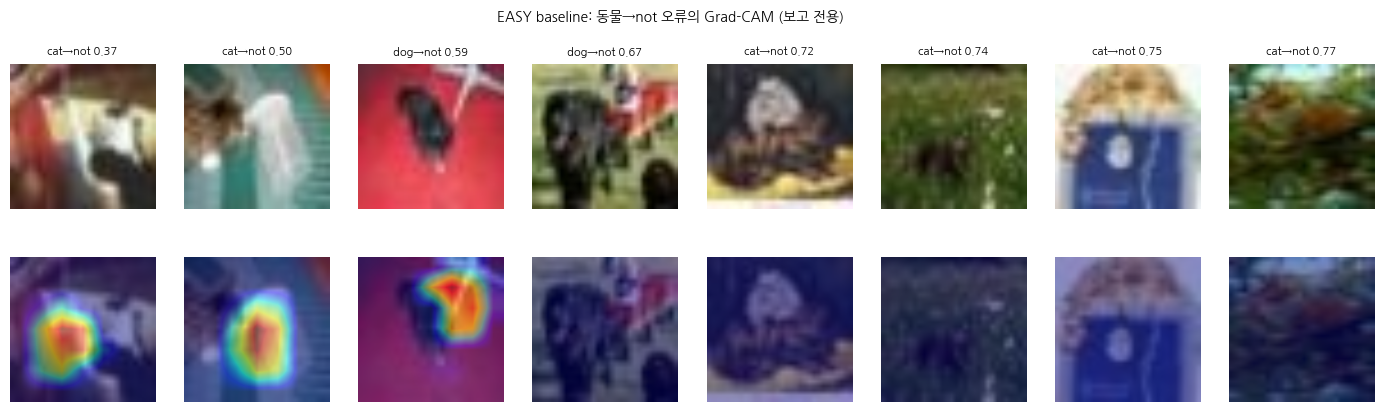

gradcam:   0%|          | 0/8 [00:00<?, ?it/s]

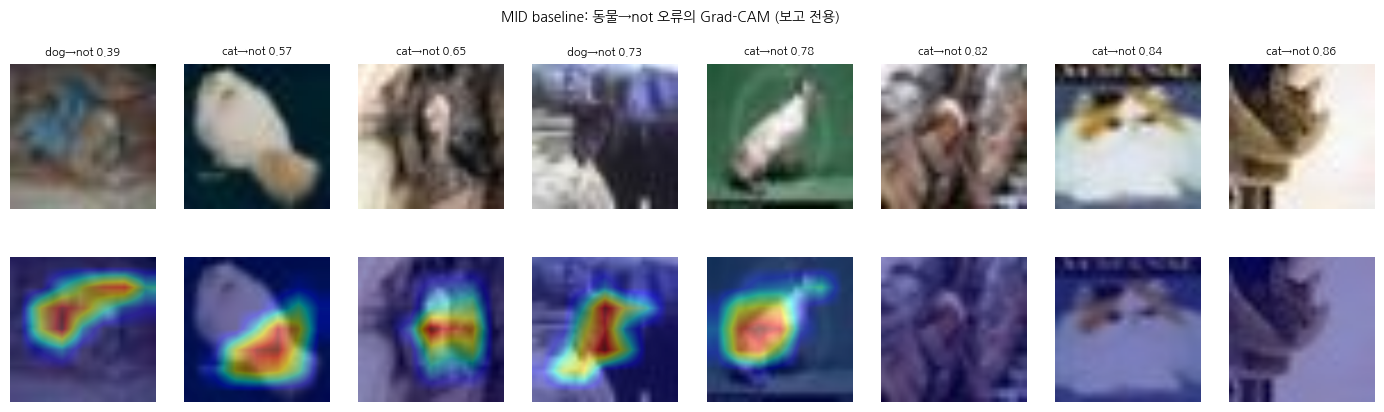

gradcam:   0%|          | 0/8 [00:00<?, ?it/s]

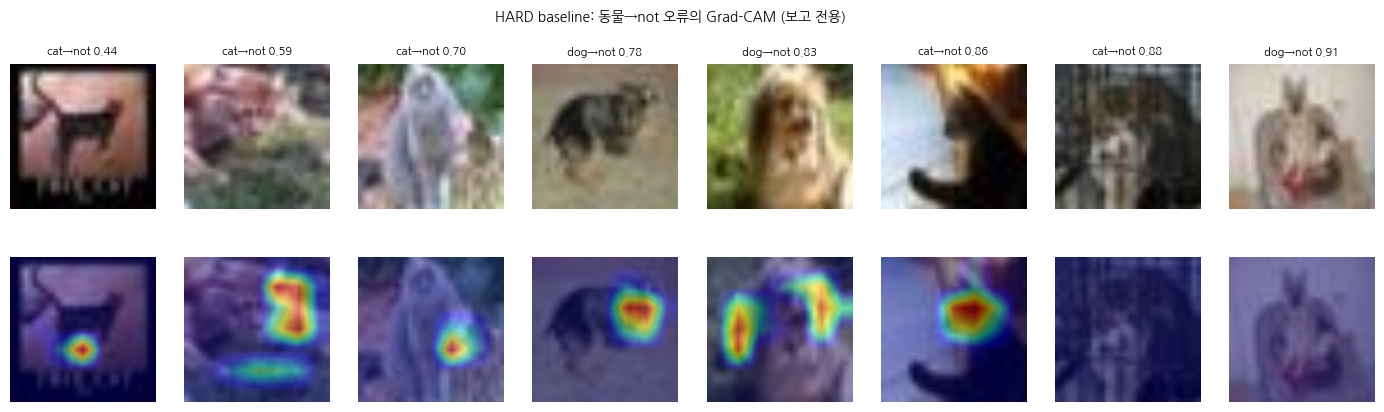

In [15]:
for _nt in NOT_TYPES:
    gradcam_gallery(_nt)